## TỔNG QUAN
### Mục tiêu

Xác định và đo lượng các yếu tố tác động đến mức độ hài lòng của khán giả đối với phim, từ đó trả lời câu hỏi: "Yếu tố nào quan trọng nhất? Ảnh hưởng bao nhiêu? Có khác biệt giữa các nhóm không?"

### Output cuối cùng
Bảng xếp hạng yếu tố quan trọng nhất (Top 10-15)
Biểu đồ thể hiện mức độ ảnh hưởng của từng yếu tố
Insights về sự khác biệt giữa các segments
Khuyến nghị cho nhà sản xuất/platform

In [68]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

import xgboost as xgb
import shap
from sklearn.metrics import mean_squared_error


In [69]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

### Tổng quan về bộ dữ liệu TMDB và Movielens

#### Bộ dữ liệu TMDB (Đặc điểm phim)

- Yếu tố định lượng (Numerical):
    - budget – Ngân sách sản xuất phim
    - revenue – Doanh thu phòng vé
    - runtime – Thời lượng phim (phút)
    - popularity – Chỉ số độ phổ biến trên TMDB
    - vote_count – Số lượng lượt đánh giá
    - vote_average - Điểm trung bình TMDB
    - vote_average – Điểm đánh giá trung bình trên TMDB

- Yếu tố định tính (Categorical):
    - genres (JSON) – Danh sách thể loại phim (Action, Drama, Comedy, …)
    - production_companies (JSON) – Các hãng sản xuất
    - production_countries (JSON) – Quốc gia sản xuất
    - original_language – Ngôn ngữ gốc của phim
    - status – Trạng thái phát hành (Released, Post Production, …)

- Yếu tố mô tả nội dung:
    - overview – Tóm tắt nội dung phim
    - tagline – Khẩu hiệu phim
    - keywords (JSON) – Tập từ khóa mô tả nội dung

- Yếu tố nhân sự:
    - cast (JSON) – Danh sách diễn viên
    - crew (JSON) – Danh sách ê-kíp sản xuất (đạo diễn, biên kịch, …)

- Biến dẫn xuất / biến xử lý thêm (Feature Engineering):
    - release_year – Năm phát hành (trích từ release_date)
    - ROI = revenue / budget – Tỷ suất lợi nhuận (đại diện cho mức độ thành công thương mại)
    - num_genres – Số lượng thể loại của mỗi phim
    - num_keywords – Số lượng từ khóa
    - cast_size – Số lượng diễn viên tham gia
    - crew_size – Quy mô ê-kíp sản xuất
    - is_franchise / sequel – Biến nhị phân xác định phim có thuộc chuỗi/phần tiếp theo hay không


In [70]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})


In [71]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [72]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


In [73]:
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew'] 

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [74]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

#### Bộ dữ liệu Movielens (Hàng vi người dùng)

Biến phụ thuộc (Target):
    - rating - Điểm đánh giá (0 - 5)

- Yếu tố người dùng:
    - age - Tuổi người dùng
    - gender - Giới tính
    - occupation - Nghề nghiệp
    - user_avg_rating - Điểm trung bình của user

- Yếu tố phim (từ MovieLens)
    - genres – Thể loại phim (có thể đa thể loại)

- Yếu tố tương tác:
    - timestamp - Thời điểm đánh giá

- Biến tổng hợp theo người dùng & phim
    - Hành vi người dùng
        - rating_count_per_user – Tổng số phim mà người dùng đã đánh giá
        - user_avg_rating – Điểm đánh giá trung bình của người dùng

    - Mức độ tương tác của phim
        - total_ratings – Tổng số lượt đánh giá của mỗi phim
        - rating_std – Độ lệch chuẩn điểm đánh giá (mức độ phân hóa ý kiến khán giả)

In [75]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

Đang tải dữ liệu...


In [76]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [77]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [78]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [79]:
# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tính toán điểm trung bình cho từng phim...


In [80]:
print("\n--- Sample Targets Movielens ---")
movie_targets.head(3)


--- Sample Targets Movielens ---


,MovieID,avg_rating
0,1,4.146846
1,2,3.201141
2,3,3.016736


## Tiền xử lý dữ liệu (Data Preprocessing)

Sau khi gộp bảng Movies và Credits, một số biến trong TMDB vẫn ở dạng JSON 
(danh sách các đối tượng).

In [81]:
def json_to_pipe(x, key='name'):
    """
    Chuyển JSON (list of dict) thành chuỗi 'a|b|c'
    """
    if pd.isna(x):
        return ''
    try:
        data = ast.literal_eval(x)
        if isinstance(data, list):
            return '|'.join([item[key] for item in data if key in item])
        return ''
    except:
        return ''

In [82]:
# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}") 
# Bây giờ chắc chắn đã có cột 'title'

Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']


In [83]:
# --- 4. MERGE METADATA ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')


Đang xử lý Metadata phim...


### Trích xuất đặc trưng (Feature Selection)

In [84]:
# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata????
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating', 
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'popularity', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

movies_final_meta.head(5)

,MovieID,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,Toy Story (1995),Animation|Children's|Comedy,1995.0,4.146846,John Lasseter,Tom Hanks,Tim Allen,Don Rickles,30000000,373554033,7.7,5269,73.640445,81.0
1,10,GoldenEye (1995),Action|Adventure|Thriller,1995.0,3.540541,Martin Campbell,Pierce Brosnan,Sean Bean,Izabella Scorupco,58000000,352194034,6.6,1174,59.824565,130.0
2,14,Nixon (1995),Drama,1995.0,3.542484,Oliver Stone,Anthony Hopkins,Joan Allen,Powers Boothe,44000000,13681765,7.1,71,3.770161,192.0
3,15,Cutthroat Island (1995),Action|Adventure|Romance,1995.0,2.458904,Renny Harlin,Geena Davis,Matthew Modine,Frank Langella,98000000,10017322,5.7,136,7.029308,119.0
4,16,Casino (1995),Drama|Thriller,1995.0,3.793255,Martin Scorsese,Robert De Niro,Sharon Stone,Joe Pesci,52000000,116112375,7.8,1307,40.066880,178.0


In [85]:
# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
# print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())
df_final.head(3)

Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 18)
5 dòng đầu tiên:


,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,4.390725,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,127.525581,133.0
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,4.154088,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,20.786616,170.0
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,3.863878,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,30.347332,131.0


### Tích hợp dữ liệu (Data Integration)

In [86]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating',                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
    'runtime', 
    'popularity'
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_final_meta.columns]
movies_lean = movies_final_meta[existing_cols]


In [87]:
# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...


### Chuẩn hóa

In [88]:
# Ta sẽ tính điểm trung bình của từng Đạo diễn/Diễn viên và gán lại cho họ.

# 1. Tạo biến "Sức mạnh Đạo diễn" (Director Power)
# Dùng transform để gán ngược lại vào từng dòng dữ liệu
full_data['director_power'] = full_data.groupby('director')['Rating'].transform('mean')

# 2. Tạo biến "Sức mạnh Diễn viên" (Actor Power)
full_data['actor_power'] = full_data.groupby('actor_1')['Rating'].transform('mean')

In [89]:

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director', 'director_power', 'actor_1', 'actor_power']
full_data[cols_check].head()

------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):


,UserID,Title,Rating,avg_rating,vote_average,director,director_power,actor_1,actor_power
0,1,One Flew Over the Cuckoo's Nest (1975),5,4.390725,8.2,Miloš Forman,4.143682,Jack Nicholson,3.757172
1,1,My Fair Lady (1964),3,4.154088,7.4,George Cukor,4.154088,Audrey Hepburn,4.154088
2,1,Erin Brockovich (2000),4,3.863878,7.1,Steven Soderbergh,3.791741,Julia Roberts,3.584800
3,1,Ben-Hur (1959),5,4.110795,5.3,Timur Bekmambetov,4.110795,Jack Huston,4.110795
4,1,Snow White and the Seven Dwarfs (1937),4,3.845347,6.9,David Hand,3.842266,Adriana Caselotti,3.845347


In [90]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   UserID          450575 non-null  int64  
 1   MovieID         450575 non-null  int64  
 2   Rating          450575 non-null  int64  
 3   Timestamp       450575 non-null  int64  
 4   Title           450575 non-null  object 
 5   Genres          450575 non-null  object 
 6   release_year    450575 non-null  float64
 7   director        450535 non-null  object 
 8   actor_1         450535 non-null  object 
 9   actor_2         450535 non-null  object 
 10  actor_3         450535 non-null  object 
 11  budget          450575 non-null  int64  
 12  revenue         450575 non-null  int64  
 13  vote_average    450575 non-null  float64
 14  vote_count      450575 non-null  int64  
 15  avg_rating      450575 non-null  float64
 16  runtime         450575 non-null  float64
 17  popularity

In [91]:
cols = full_data.columns
print(len(cols))
# Output: Index(['budget', 'revenue', 'runtime', ...], dtype='object')

20


In [92]:
full_data.head()

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,runtime,popularity,director_power,actor_power
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,133.0,127.525581,4.143682,3.757172
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,170.0,20.786616,4.154088,4.154088
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,131.0,30.347332,3.791741,3.584800
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,125.0,29.608322,4.110795,4.110795
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,83.0,80.171283,3.842266,3.845347


### Làm sạch dữ liệu (Data Cleaning)

In [93]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID             0
MovieID            0
Rating             0
Timestamp          0
Title              0
Genres             0
release_year       0
director          40
actor_1           40
actor_2           40
actor_3           40
budget             0
revenue            0
vote_average       0
vote_count         0
avg_rating         0
runtime            0
popularity         0
director_power    40
actor_power       40
dtype: int64

In [94]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 20)
 Số dòng bị thiếu: 
UserID            0
MovieID           0
Rating            0
Timestamp         0
Title             0
Genres            0
release_year      0
director          0
actor_1           0
actor_2           0
actor_3           0
budget            0
revenue           0
vote_average      0
vote_count        0
avg_rating        0
runtime           0
popularity        0
director_power    0
actor_power       0
dtype: int64


In [95]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [96]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) & 
    (full_data['budget'] > 10000) & 
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

### Phân tích đơn biến

Câu hỏi cần trả lời:
+ Rating có phân bố chuẩn không? (normal distribution)
+ Có outliers không?
+ Có imbalance trong categorical variables không?

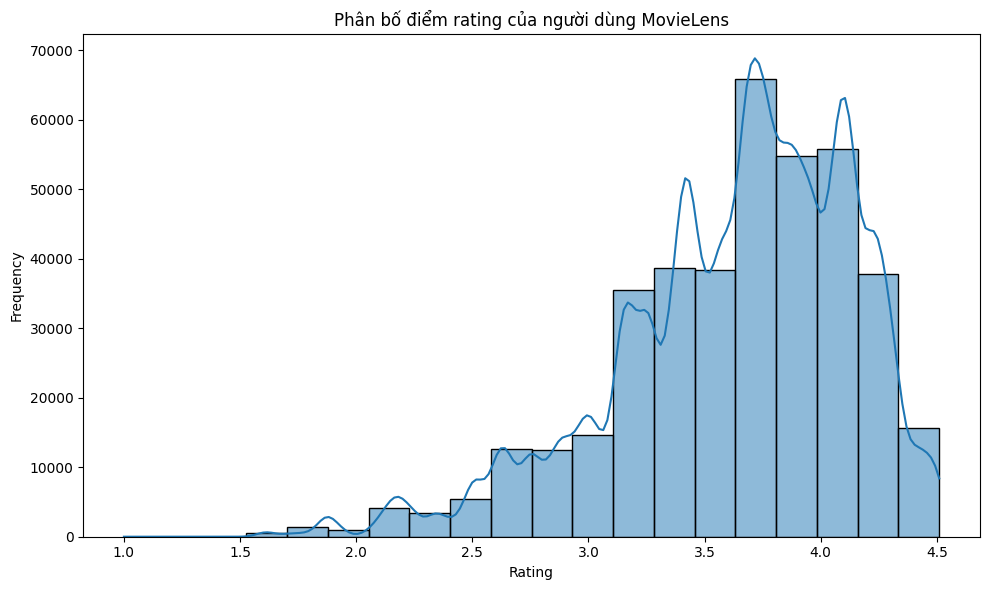

In [97]:
# Phân bố biến mục tiêu
plt.figure(figsize=(10, 6))
sns.histplot(full_data['avg_rating'], bins=20, kde=True)
plt.title('Phân bố điểm rating của người dùng MovieLens')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


Biểu đồ phân bố điểm rating cho thấy dữ liệu lệch trái rõ rệt:

+ Tần suất thấp ở các mức điểm thấp (1.0–2.5) và tăng mạnh ở các mức điểm cao. Phần lớn đánh giá tập trung trong khoảng 3.0–4.5, với các cột vượt 30.000 lượt. Đỉnh cao nhất xuất hiện tại mức 4.0, đạt khoảng 65.000–70.000 lượt, tiếp theo là các đỉnh tại 3.0 và 3.5. Sau mức 4.0, tần suất giảm dần ở 4.5. 

+ Đường cong mật độ bám sát các cột và gợn sóng theo các mức điểm nguyên và bán nguyên, phản ánh xu hướng đánh giá tập trung vào các mốc điểm quen thuộc.

In [98]:
# 2. Thống kê mô tả
print(full_data['Rating'].describe())
print(f"Skewness: {full_data['Rating'].skew():.3f}")
print(f"Kurtosis: {full_data['Rating'].kurtosis():.3f}")


count    397975.000000
mean          3.630100
std           1.106728
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: Rating, dtype: float64
Skewness: -0.591
Kurtosis: -0.292


- Kết quả thống kê mô tả cho thấy điểm rating trung bình của người dùng MovieLens đạt 3.63 trên thang điểm 5. 
Giá trị trung vị và tứ phân vị trên đều bằng 4.0, cho thấy phần lớn các bộ phim được đánh giá ở mức khá đến tốt.

- Phân bố rating có độ lệch trái nhẹ (skewness = -0.591), phản ánh xu hướng người dùng chấm điểm cao nhiều hơn điểm thấp.
Hệ số kurtosis âm (-0.293) cho thấy phân bố có đỉnh thấp và trải rộng hơn so với phân bố chuẩn, không xuất hiện hiện tượng tập trung quá mức quanh giá trị trung bình.

- Nhìn chung, phân bố rating không hoàn toàn tuân theo phân bố chuẩn nhưng không có sự lệch cực đoan, cho phép áp dụng các phương pháp phân tích thống kê và mô hình hóa trong các bước tiếp theo.


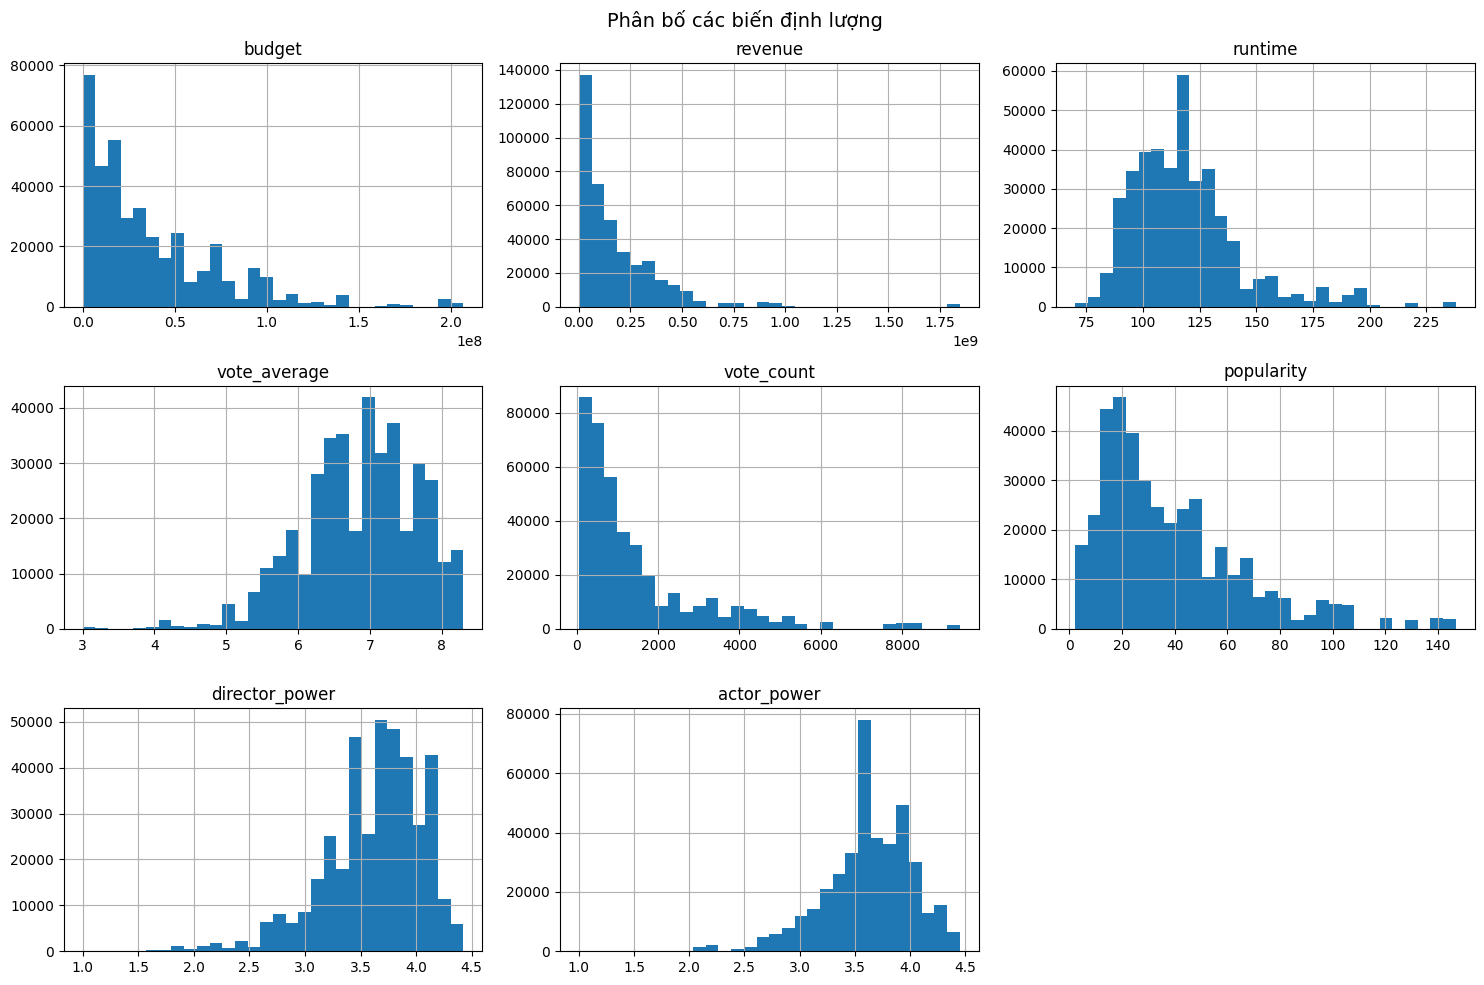

In [99]:
# 3. Phân bố các biến numerical khác
numerical_cols = [
    'budget', 
    'revenue', 
    'runtime', 
    'vote_average', 
    'vote_count',
    'popularity',
    'director_power',
    'actor_power'
]

full_data[numerical_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle('Phân bố các biến định lượng', fontsize=14)
plt.tight_layout()
plt.show()


Nhóm biến lệch phải mạnh (budget, revenue, vote_count, popularity):
Các biến này đều có phân bố lệch phải rõ rệt. Phần lớn phim nằm ở mức thấp đến trung bình, trong khi chỉ một số ít phim bom tấn hoặc rất nổi tiếng có giá trị cực cao, tạo ra đuôi dài. Đây là đặc trưng phổ biến của ngành điện ảnh, phản ánh sự chênh lệch lớn giữa phim đại chúng và số ít tác phẩm dẫn đầu thị trường.

Nhóm biến tập trung và tương đối ổn định (runtime, director_power, actor_power):
Thời lượng phim phân bố khá tập trung, gần dạng chuông, chủ yếu trong khoảng 90–130 phút, cho thấy cấu trúc thời lượng phim điện ảnh tương đối đồng nhất. Tương tự, các biến director_power và actor_power cũng có phân bố tập trung quanh các giá trị trung bình, phản ánh rằng phần lớn phim được thực hiện bởi các đạo diễn và diễn viên có mức độ ảnh hưởng trung bình, trong khi chỉ một số ít cá nhân có sức ảnh hưởng vượt trội.

Nhóm biến phản ánh cảm nhận người xem (vote_average):
Điểm đánh giá trung bình tập trung nhiều ở khoảng 6–8 điểm, đây là điểm được chấm từ TMDB, cho thấy xu hướng người dùng đánh giá phim khá tích cực. Các mức điểm quá thấp hoặc quá cao xuất hiện ít, phản ánh sự đồng thuận tương đối trong cảm nhận chất lượng phim.

Sự xuất hiện dày đặc của các giá trị ngoại lai (outliers) ở nhóm biến tài chính và mức độ phổ biến chính là minh chứng rõ nét cho phân phối "đuôi dài" (long-tail) đặc thù của ngành công nghiệp điện ảnh. Những giá trị này không phải là nhiễu, mà đại diện cho các bộ phim "bom tấn" nằm tách biệt hoàn toàn so với mặt bằng chung, tạo ra sự chênh lệch cực lớn về quy mô và sức ảnh hưởng. Chính sự hiện diện của những ngoại lai này đã kéo dãn đồ thị về phía bên phải, gây ra hiện tượng lệch phân phối, đòi hỏi các phương pháp xử lý dữ liệu đặc thù để mô hình không bị thiên lệch bởi thiểu số các siêu phẩm này.



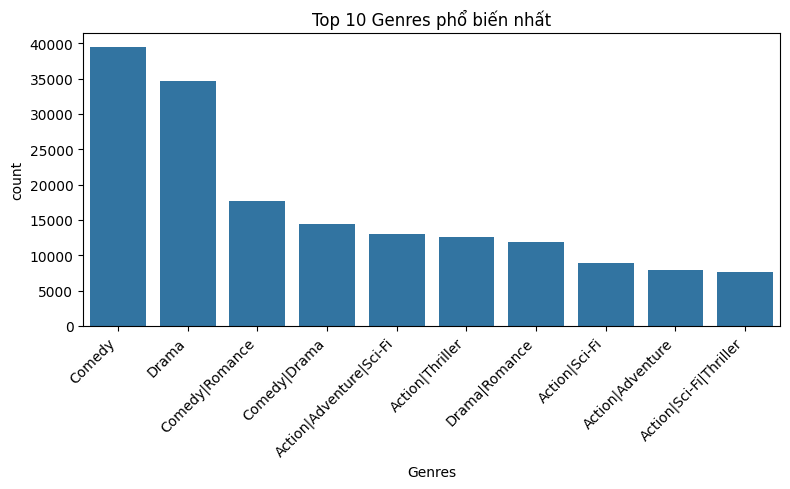

In [100]:
import seaborn as sns
import matplotlib.pyplot as plt

# 4. Tần suất của các biến phân loại
categorical_cols = ['Genres']

for col in categorical_cols:
    top_values = full_data[col].value_counts().head(10).reset_index()
    top_values.columns = [col, 'count']

    plt.figure(figsize=(8, 5))
    sns.barplot(data=top_values, x=col, y='count')
    plt.title(f'Top 10 {col} phổ biến nhất')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Genres distribution đã xác nhận có tồn tại tình trạng sự mất cân bằng trong biến phân loại (Categorical imbalance). Số lượng phim thuộc thể loại Comedy (gần 40.000) và Drama (gần 35.000) áp đảo hoàn toàn so với các thể loại phức hợp như Action|Sci-Fi|Thriller (chỉ khoảng 7.000). Sự chênh lệch lớn về tần suất xuất hiện giữa các nhóm này chính là biểu hiện rõ nhất của mất cân bằng dữ liệu, điều này sẽ ảnh hưởng lớn nếu dùng Genre làm biến mục tiêu để dự đoán.

### Phân tích hai biến

Insights cần tìm:
+ Biến nào có correlation mạnh với rating?
+ Có non-linear relationships không?

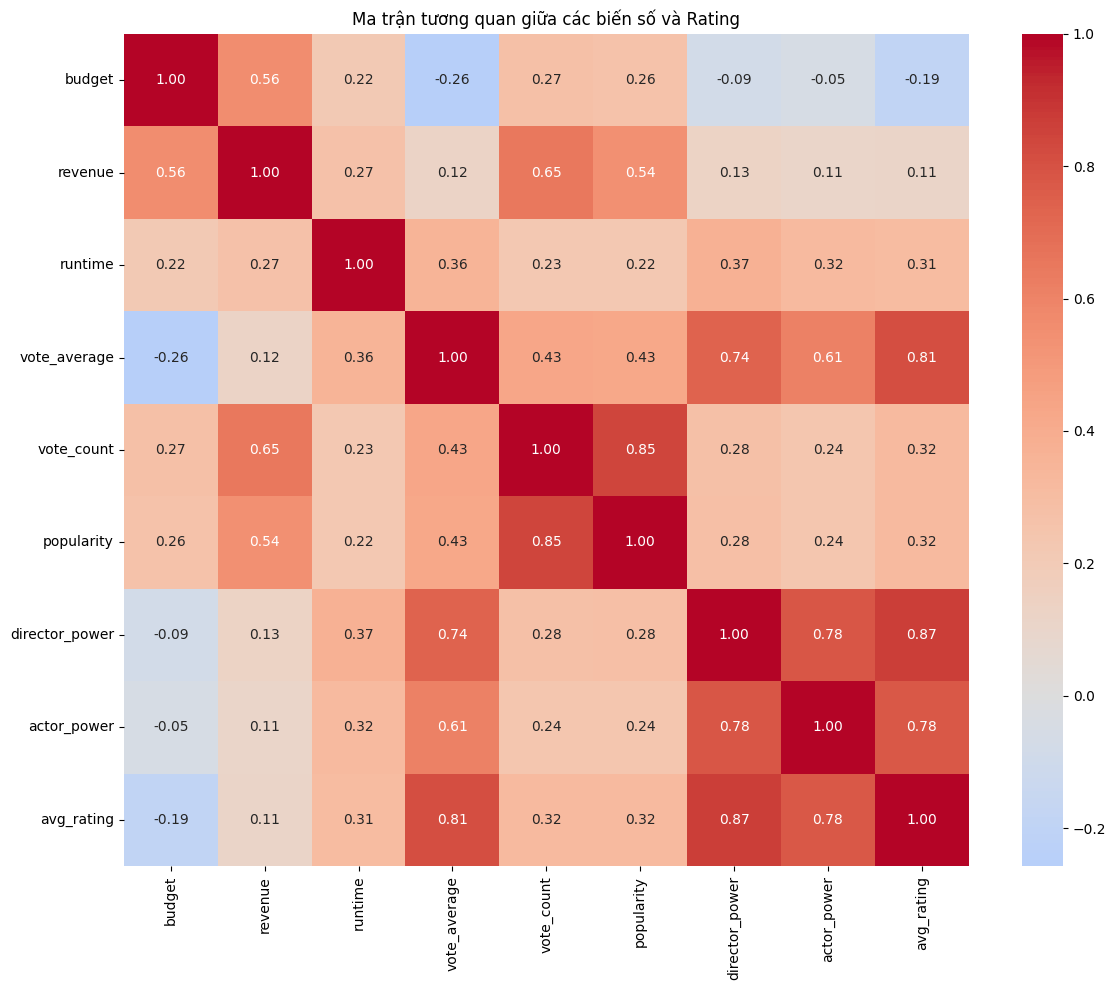

In [101]:
plt.figure(figsize=(12, 10))

corr_cols = numerical_cols + ['avg_rating']
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()
correlation_matrix = df_movie_scope[corr_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0
)

plt.title('Ma trận tương quan giữa các biến số và Rating')
plt.tight_layout()
plt.show()


Biến số Director Power có hệ số tương quan dương cao nhất (0.87), khẳng định rằng thương hiệu và tài năng của đạo diễn chính là "tấm tem bảo hành" uy tín nhất cho chất lượng phim trên MovieLens, quan trọng hơn rất nhiều so với số tiền đổ vào sản xuất. 

Actor Power cũng ghi nhận mức tương quan rất mạnh (0.78), cho thấy một dàn diễn viên thực lực không chỉ giúp bộ phim thu hút sự chú ý mà còn đóng góp trực tiếp vào giá trị nghệ thuật, tạo nên sự cộng hưởng mạnh mẽ giúp nâng cao điểm số đánh giá cuối cùng.

Mối tương quan cùng chiều cực mạnh (0.81) giữa avg_rating và vote_average, khẳng định rằng đánh giá của người dùng trên MovieLens rất đồng nhất với điểm số đại chúng trên TMDB. 

Điểm số trung bình cũng có mối liên hệ tích cực vừa phải với thời lượng phim (0.31) và số lượt bình chọn (0.32), gợi ý rằng các bộ phim có thời lượng dài hơn (thường là phim có chiều sâu) và được nhiều người quan tâm thường có chất lượng tốt hơn.

Ngược lại, các yếu tố tài chính lại cho thấy mối liên hệ rất yếu, thậm chí là tiêu cực với chất lượng phim:

+ Doanh thu (Revenue) gần như không ảnh hưởng đến điểm số (0.11), trong khi ngân sách (Budget) lại có tương quan âm nhẹ (-0.19). Điều này phản ánh một thực tế thú vị: phim được đầu tư "khủng" chưa chắc đã hay, thậm chí đôi khi ngân sách càng cao thì điểm đánh giá lại càng thấp hơn so với kỳ vọng.

+ Sự phụ thuộc lẫn nhau giữa các biến độc lập, chẳng hạn như phim có doanh thu cao thường đi kèm với lượng tương tác lớn (0.65) và ngân sách lớn (0.56).

Mối tương quan cùng chiều mạnh mẽ đến mức kinh ngạc giữa sức mạnh của đạo diễn, diễn viên với điểm đánh giá đã đảo chiều hoàn toàn tư duy phân tích, khẳng định rằng uy tín của người kể chuyện có sức nặng gấp nhiều lần số tiền họ chi ra.

Điều này buộc chúng ta phải đặt lại vấn đề: Liệu khán giả đang thực sự thưởng thức tác phẩm một cách khách quan, hay họ đang chấm điểm dựa trên "bảo chứng niềm tin" tuyệt đối dành cho những cái tên huyền thoại đứng sau ống kính?

Thực hiện: chia các đạo diễn thành các nhóm (Phân khúc) dựa trên sức mạnh của họ (ví dụ: Vô danh, Triển vọng, Nổi tiếng, Huyền thoại). Sau đó, kiểm tra xem: Khi một đạo diễn "Huyền thoại" làm một bộ phim không quá nổi bật (Popularity thấp) hoặc doanh thu thấp, liệu khán giả có "dám" chấm điểm thấp cho họ không?

Nếu đạo diễn hạng thấp làm phim dở thì bị chấm 1-2 điểm, nhưng đạo diễn "Huyền thoại" làm phim dở vẫn được chấm 3.5 điểm -> Đó chính là "Bảo chứng niềm tin".

Tỷ lệ bị chấm điểm thấp (Rating < 2.5) theo đẳng cấp đạo diễn:
  Director Tier  Flop Rate (%)
0           Low      10.596931
1        Medium       1.108695
2          High       0.184461
3     Legendary       0.000000


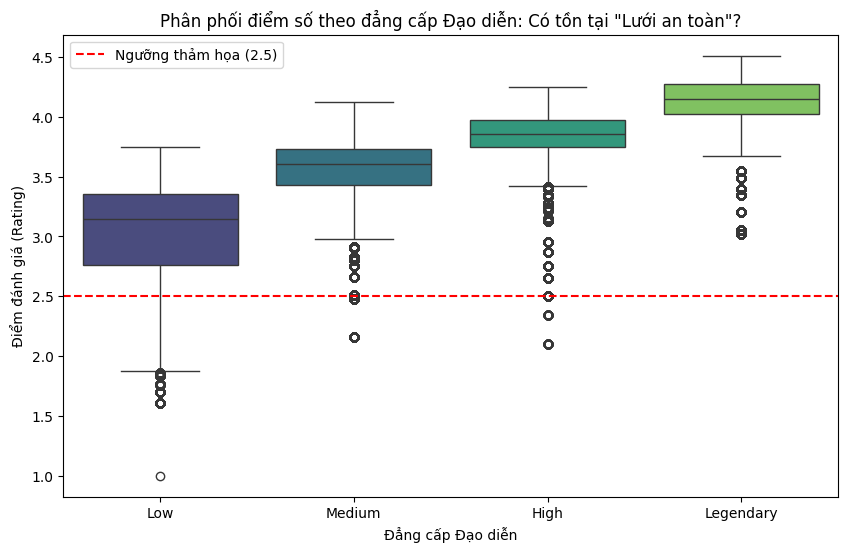

In [102]:
# 1. Phân loại Đạo diễn thành 4 đẳng cấp (Quartiles)
# Low: Vô danh, Medium: Triển vọng, High: Nổi tiếng, Legendary: Huyền thoại
full_data['director_tier'] = pd.qcut(full_data['director_power'], q=4, labels=['Low', 'Medium', 'High', 'Legendary'])

# 2. Tính toán "Tỷ lệ thảm họa" (Flop Rate) cho từng nhóm
# Giả sử phim "thảm họa" là phim có rating < 2.5
flop_threshold = 2.5
flop_analysis = full_data.groupby('director_tier')['avg_rating'].apply(lambda x: (x < flop_threshold).mean() * 100).reset_index()
flop_analysis.columns = ['Director Tier', 'Flop Rate (%)']

print("Tỷ lệ bị chấm điểm thấp (Rating < 2.5) theo đẳng cấp đạo diễn:")
print(flop_analysis)

# 3. Trực quan hóa "Lưới an toàn" (Safety Net) bằng Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x='director_tier', y='avg_rating', data=full_data, palette="viridis")

plt.title('Phân phối điểm số theo đẳng cấp Đạo diễn: Có tồn tại "Lưới an toàn"?')
plt.ylabel('Điểm đánh giá (Rating)')
plt.xlabel('Đẳng cấp Đạo diễn')
plt.axhline(y=2.5, color='r', linestyle='--', label='Ngưỡng thảm họa (2.5)')
plt.legend()
plt.show()



Nhóm Low (Vô danh): Rất nhiều phim của họ rơi tự do xuống dưới vạch đỏ này (các chấm tròn ngoại lai kéo dài xuống tận 1.0). Điều này có nghĩa là khi họ làm phim dở, khán giả sẵn sàng trừng phạt họ bằng những điểm số tệ hại nhất.

Nhóm Legendary (Huyền thoại): Đây là điều thú vị nhất. Toàn bộ hộp và râu (whiskers) của nhóm này nằm cao chót vót. Quan trọng hơn, ngay cả những điểm chấm tròn thấp nhất (đại diện cho các phim "tệ nhất" của họ - outliers) cũng chỉ dừng lại ở mức 3.0, tức là vẫn cao hơn hẳn so với ngưỡng thảm họa.

-> Đạo diễn huyền thoại có một "tấm khiên" vô hình. Dù phim của họ có tệ đến đâu so với tiêu chuẩn của chính họ, khán giả vẫn mặc định chấm mức điểm Khá (3.0) chứ không bao giờ dìm xuống mức Yếu/Kém.

In [103]:
# 4. Phân tích độ lệch chuẩn (Consistency)
# Xem ai ổn định hơn: Người xem có xu hướng chấm điểm "đồng lòng" cho Legendary không?
std_analysis = full_data.groupby('director_tier')['avg_rating'].std().reset_index()
std_analysis.columns = ['Director Tier', 'Rating Std Dev']
print("\nĐộ lệch chuẩn điểm số (Sự nhất quán trong đánh giá):")
print(std_analysis)


Độ lệch chuẩn điểm số (Sự nhất quán trong đánh giá):
  Director Tier  Rating Std Dev
0           Low        0.425808
1        Medium        0.318242
2          High        0.267535
3     Legendary        0.263415


Xu hướng giảm dần: Độ lệch chuẩn (Std Dev) giảm đều đặn từ mức cao nhất 0.425 (Low) xuống mức thấp nhất 0.263 (Legendary).

Ý nghĩa: Trong thống kê, độ lệch chuẩn càng thấp nghĩa là dữ liệu càng ít biến động xung quanh giá trị trung bình.

+ Với nhóm Low (0.425): Khoảng điểm dao động rất rộng, giống như chơi xổ số, rủi ro cao.

+ Với nhóm Legendary (0.263): Điểm số cực kỳ cô đọng và nhất quán. Khán giả có sự đồng thuận cao độ khi đánh giá phim của họ, hiếm khi có sự tranh cãi gay gắt (người khen nức nở, kẻ chê thậm tệ) như các nhóm dưới.

Nếu như nhóm Legendary đại diện cho sự hoàn hảo được mặc định, thì nhóm High lại mang những chỉ số thống kê đầy mâu thuẫn nhưng cực kỳ thú vị. Một mặt, độ lệch chuẩn thấp cho thấy họ đã đạt đến đẳng cấp kiểm soát chất lượng gần như tuyệt đối, thoát ly hoàn toàn khỏi sự phập phù của nhóm Vô danh. Nhưng mặt khác, những điểm dữ liệu "xuyên đáy" vượt qua ngưỡng an toàn lại tố cáo một thực tế tàn nhẫn: dù tài năng đến đâu, họ vẫn chưa đủ quyền lực để khiến khán giả nhắm mắt làm ngơ trước những sai lầm.

Mối tương quan 0.31 giữa thời lượng và điểm số gợi mở giả thuyết rằng khán giả thường ưu ái những tác phẩm dài hơi có chiều sâu hơn là phim giải trí ngắn. Dùng boxplot để kiểm chứng:

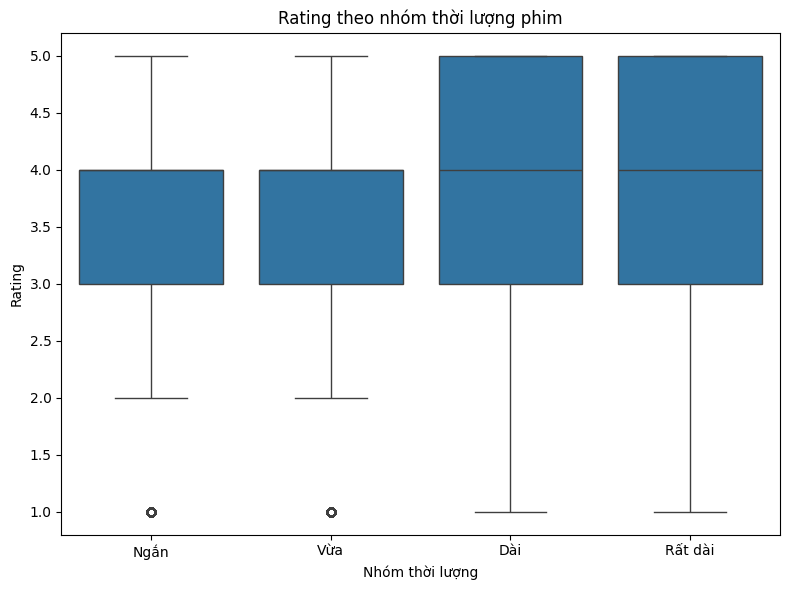

In [104]:
full_data['runtime_group'] = pd.cut(
    full_data['runtime'],
    bins=[0, 90, 120, 150, 300],
    labels=['Ngắn', 'Vừa', 'Dài', 'Rất dài']
)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=full_data,
    x='runtime_group',
    y='Rating'
)

plt.title('Rating theo nhóm thời lượng phim')
plt.xlabel('Nhóm thời lượng')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()


Nhóm phim ngắn và vừa có trung vị khoảng 3.5, với khoảng phân bố hẹp hơn, cho thấy mức đánh giá tương đối ổn định nhưng không quá cao. Một số ngoại lệ có điểm rất thấp (khoảng 1 sao) xuất hiện ở hai nhóm này.

Trong khi đó, nhóm phim dài và rất dài có trung vị cao hơn, xấp xỉ 4.0, đồng thời độ phân tán lớn hơn, phản ánh sự đa dạng trong đánh giá của người xem. Dù vẫn tồn tại các phim bị chấm điểm thấp, phần lớn phim dài và rất dài có xu hướng nhận đánh giá tích cực hơn.

Nhìn chung, kết quả cho thấy phim có thời lượng dài hơn thường được đánh giá cao hơn, có thể do nội dung được phát triển sâu hơn, dù mức độ rủi ro cũng tăng khi chất lượng không đồng đều.

Bên cạnh đó vẫn còn những yếu tố phân loại, cùng xem xét sự tương quan của nó đến rating trung bình:

+ Độ tuổi:

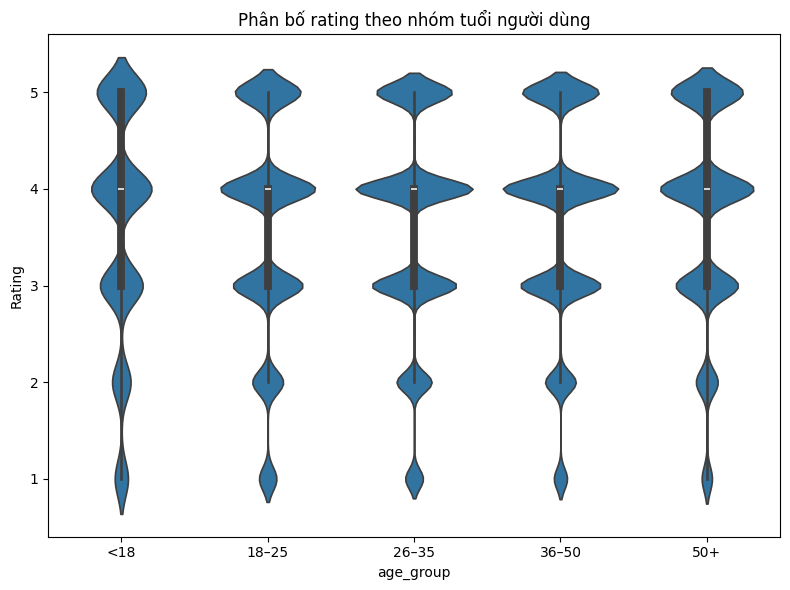

In [105]:
bins = [0, 18, 25, 35, 50, 100]
labels = ['<18', '18–25', '26–35', '36–50', '50+']

users['age_group'] = pd.cut(
    users['Age'],
    bins=bins,
    labels=labels,
    right=False
)

full_data = full_data.merge(
    users[['UserID', 'Gender', 'age_group']],
    on='UserID',
    how='left'
)

plt.figure(figsize=(8, 6))
sns.violinplot(
    data=full_data,
    x='age_group',
    y='Rating'
)

plt.title('Phân bố rating theo nhóm tuổi người dùng')
plt.tight_layout()
plt.show()

Kết quả cho thấy một sự đồng nhất đáng ngạc nhiên trong hành vi chấm điểm giữa tất cả các nhóm tuổi. Dù là nhóm trẻ nhất (<18) hay nhóm lớn tuổi nhất (50+), hình dáng của biểu đồ violin gần như y hệt nhau. Cụ thể, dữ liệu tập trung dày đặc (phần phình to nhất của biểu đồ) ở các mốc điểm 3.0, 4.0 và 5.0, trong khi phần đuôi ở các điểm thấp (1.0, 2.0) rất thon nhỏ. Giá trị trung vị (thể hiện qua chấm trắng hoặc vạch giữa) của tất cả các nhóm đều neo ổn định ở mức 4.0.

-> Tuổi tác không phải là yếu tố phân biệt mạnh đối với việc người dùng đánh giá phim cao hay thấp. Một thiếu niên và một người trung niên trong tập dữ liệu này có xu hướng "hào phóng" như nhau khi chấm điểm.


+ Giới tính:

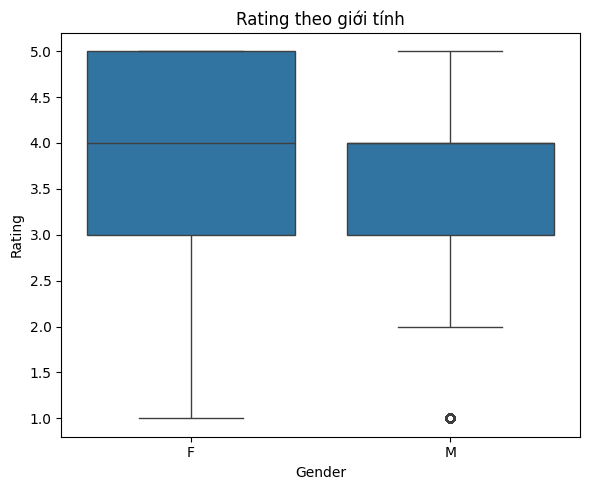

In [106]:
plt.figure(figsize=(6, 5))
sns.boxplot(
    data=full_data,
    x='Gender',
    y='Rating'
)

plt.title('Rating theo giới tính')
plt.tight_layout()
plt.show()



Trung vị (median) của cả hai giới tính đều nằm ở mức 4.0 (đường gạch ngang giữa hộp). Tuy nhiên, sự khác biệt bắt đầu lộ diện ở độ rộng của hộp (Interquartile Range - IQR). Nhóm Nữ (F) có vùng dữ liệu tập trung trải rộng hơn từ 3.0 đến 5.0, trong khi nhóm Nam (M) lại co cụm hẹp hơn chỉ từ 3.0 đến 4.0.

Cho thấy Nữ giới có xu hướng "hào phóng" hoặc phân cực hơn trong việc chấm điểm; họ sẵn sàng cho điểm tuyệt đối (5.0) nhiều hơn, khiến cạnh trên của hộp chạm mốc tối đa. Ngược lại, Nam giới tỏ ra thận trọng và khắt khe hơn, điểm số của họ ổn định cao ở mức khá (3-4 điểm) nhưng ít khi chạm ngưỡng xuất sắc trong nhóm phổ thông (75% dữ liệu nằm dưới mức 4.0). 

-> Mặc dù không quá lớn, nhưng sự khác biệt về phương sai (variance) này cho thấy biến user_gender có giá trị hơn so với age_group. Mô hình có thể học được rằng nếu là user nữ, xác suất xuất hiện điểm 5.0 sẽ nhỉnh hơn so với user nam.

+ Thể loại:

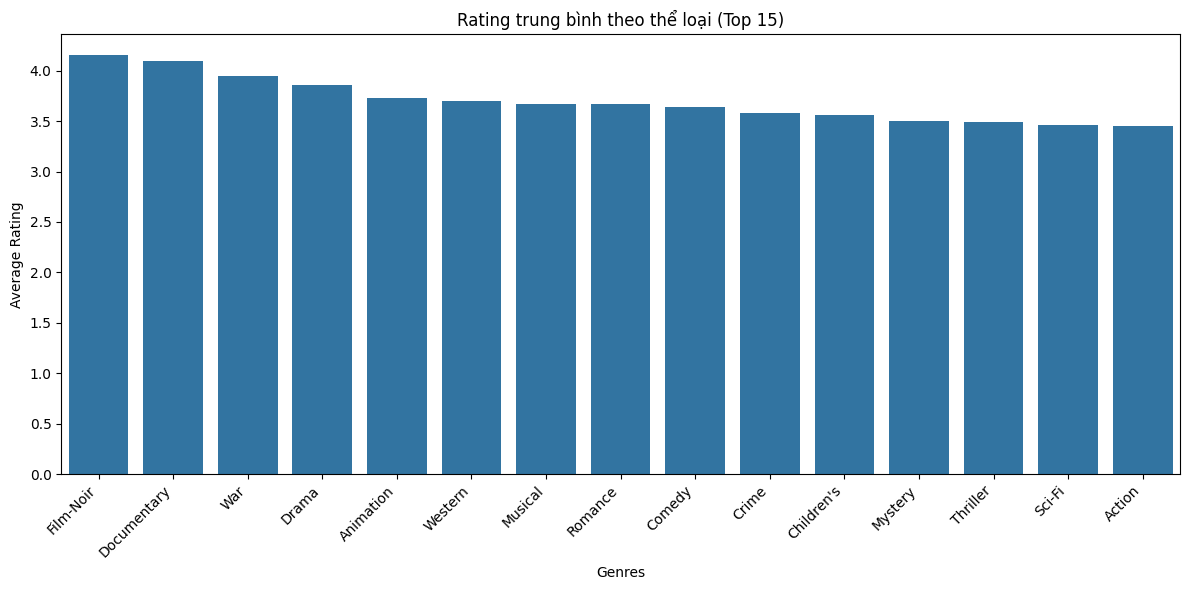

In [107]:
genre_df = full_data[['Genres', 'Rating']].copy()
genre_df['Genres'] = genre_df['Genres'].str.split('|')
genre_df = genre_df.explode('Genres')

genre_rating = genre_df.groupby('Genres')['Rating'].agg(
    mean='mean',
    count='count',
    std='std'
)

genre_rating = genre_rating[genre_rating['count'] > 1000] \
    .sort_values('mean', ascending=False) \
    .head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=genre_rating.index,
    y=genre_rating['mean']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Average Rating')
plt.title('Rating trung bình theo thể loại (Top 15)')
plt.tight_layout()
plt.show()


Nhóm thể loại có điểm trung bình cao nhất là Film-Noir và Documentary, đều đạt trên 4.0, cho thấy các phim thuộc nhóm này thường được đánh giá cao về nội dung và chiều sâu. Tiếp theo là War và Drama, với mức rating xấp xỉ từ 3.9 đến 4.0, phản ánh sự đánh giá tích cực của người xem đối với các thể loại giàu tính cảm xúc và giá trị nghệ thuật.

Các thể loại phổ biến như Animation, Western, Musical, Romance và Comedy có rating trung bình dao động quanh 3.6–3.7, thể hiện mức độ hài lòng khá tốt nhưng không nổi trội.

Ở nhóm cuối, Action, Sci-Fi, Thriller và Mystery có rating trung bình thấp hơn, khoảng 3.4–3.5. Điều này cho thấy dù thu hút đông đảo khán giả, các thể loại thiên về giải trí và kỹ xảo thường khó đạt điểm đánh giá cao như những thể loại chú trọng nội dung và thông điệp.

Cho thấy khán giả MovieLens có xu hướng đánh giá khắt khe hơn với các dòng phim thị trường (Action, Sci-Fi) và dành sự trân trọng đặc biệt cho các tác phẩm nghệ thuật hoặc phim tài liệu. Một bộ phim "Film-Noir" ngẫu nhiên có xác suất được đánh giá cao hơn nhiều so với một bộ phim "Action" ngẫu nhiên.

-> Khác với biến độ tuổi (Age Group) gần như phẳng lì, biến Genre cho thấy khả năng phân loại (discriminative power) rất tốt. Việc biết một bộ phim thuộc thể loại Documentary hay Action sẽ thay đổi đáng kể kỳ vọng về điểm số. Do đó, đây chắc chắn là một biến quan trọng (high feature importance) cần được xử lý kỹ (ví dụ: One-Hot Encoding hoặc Target Encoding) để đưa vào mô hình.

Trong heatmap, budget có tương quan âm nhẹ (-0.19) với rating, nhưng điều này không có nghĩa là cứ giảm tiền thì phim sẽ hay. Rất có thể mối quan hệ này mang hình dạng đường cong (curvilinear) hoặc có điểm bão hòa:

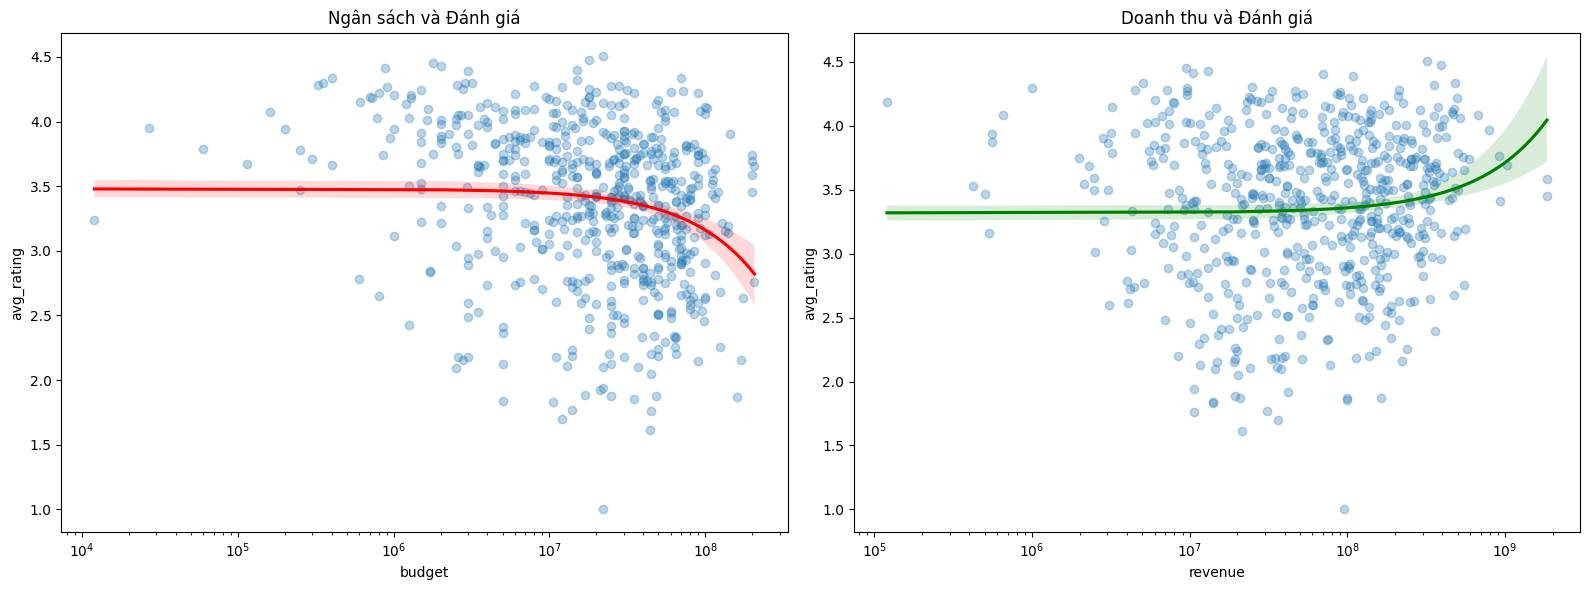

In [108]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()

Hiệu ứng ngược của Ngân sách (Đường đỏ): Xuất hiện xu hướng phi tuyến tính rõ rệt. Điểm đánh giá đi ngang ở mức ngân sách thấp và trung bình, nhưng bắt đầu giảm dần khi ngân sách tăng lên mức cực cao (trên $10^8$). Điều này cho thấy các phim "bom tấn" kinh phí khủng thường không được đánh giá cao về chất lượng nội dung.

Sự đồng thuận của Doanh thu (Đường xanh): Có mối quan hệ tương quan dương phi tuyến tính. Doanh thu càng cao, đường xu hướng càng đi lên, chứng tỏ các bộ phim thành công về mặt thương mại thường cũng là những phim có chất lượng tốt và được khán giả yêu thích.

Tính phi tuyến tính hiện diện rõ rệt qua hai đường cong đối lập trên biểu đồ. Trong khi ngân sách tuân theo quy luật "hiệu suất giảm dần" với đường xu hướng uốn xuống ở mức đầu tư siêu cao, thì doanh thu lại vẽ nên đường cong dốc lên, cho thấy sự đồng biến mạnh mẽ với chất lượng ở phân khúc "tỷ đô". Từ đó rút ra: "Tiền không mua được chất lượng nghệ thuật". Có một ngưỡng chi phí "tối ưu" (khoảng 10-50 triệu USD) nơi các nhà làm phim cân bằng tốt nhất giữa chất lượng sản xuất và tự do sáng tạo. Vượt qua ngưỡng này, áp lực thương mại khiến nội dung trở nên an toàn và sáo rỗng, kéo tụt điểm số.

### Phân tích đa biến

Insights cần tìm:
+ Có interaction effects không? (VD: budget cao + action genre = rating cao)

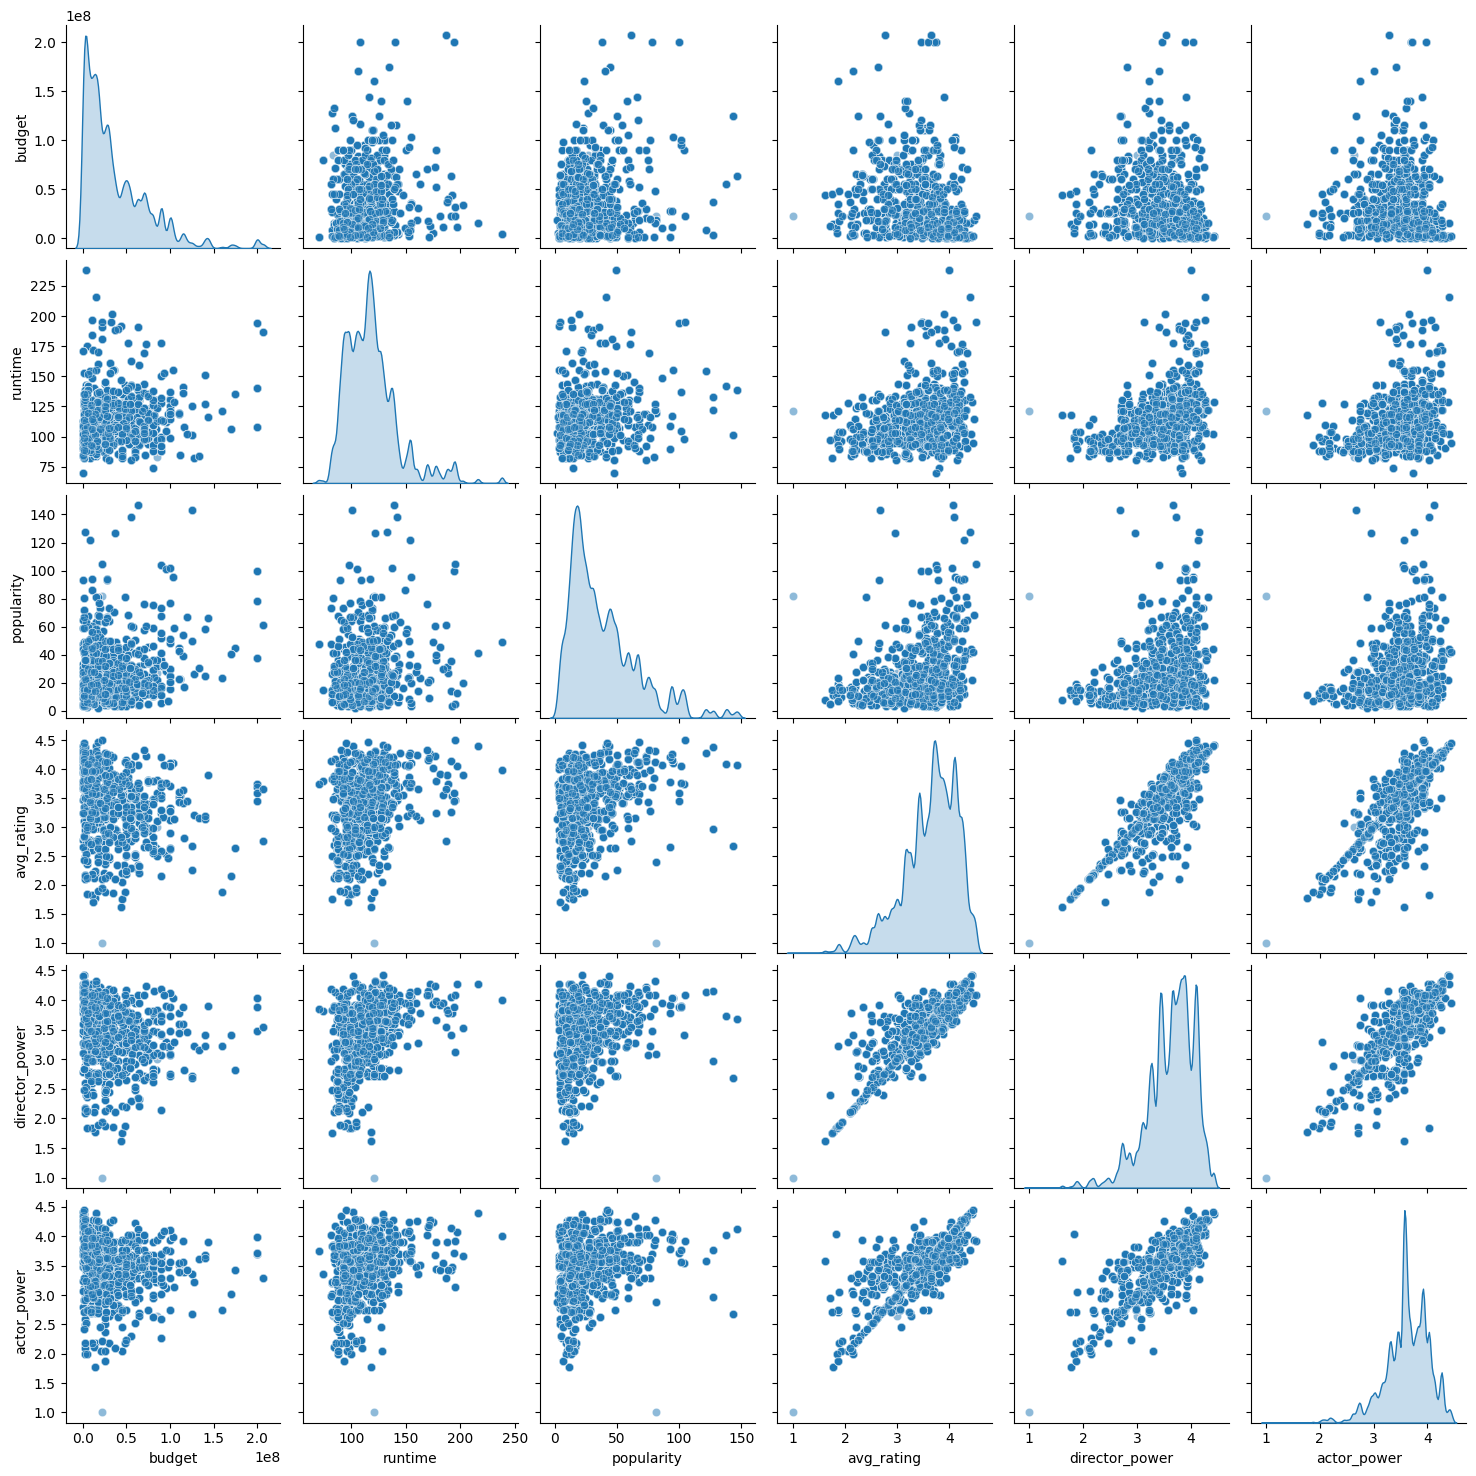

In [109]:
# 1. Pairplot cho top features
top_features = ['budget', 'runtime', 'popularity', 'avg_rating', 'director_power', 'actor_power']
sns.pairplot(full_data[top_features], diag_kind='kde', plot_kws={'alpha': 0.5})
plt.show()

Dữ liệu đã chứng minh tiền bạc có thể mua được sự nổi tiếng nhưng không thể mua được điểm số cao. Mối quan hệ giữa ngân sách và chất lượng hoàn toàn lỏng lẻo, cho thấy khán giả quan tâm đến trải nghiệm nội dung hơn là quy mô sản xuất. Ngược lại, thời lượng và độ phổ biến đang cho thấy những tín hiệu hứa hẹn hơn để giải thích cho sự thành công của một bộ phim.

Mối quan hệ giữa Sức mạnh Đạo diễn và Điểm đánh giá tạo thành một dải hẹp dốc lên rất rõ nét, khẳng định đây là yếu tố dự báo chính xác nhất cho chất lượng phim. Tương tự, Sức mạnh Diễn viên cũng song hành chặt chẽ với điểm số, và thú vị hơn là sự tương quan mạnh giữa chính Đạo diễn và Diễn viên, cho thấy tài năng thường có xu hướng hội tụ để cùng tạo nên những tác phẩm xuất sắc, tách biệt hoàn toàn với sự ngẫu nhiên của yếu tố tài chính.

Vậy bên cạnh yếu tố như đạo diễn hay diễn viên, yếu tố nào còn góp phần thúc đẩy rating? Là giá trị nội tại của câu chuyện (đại diện bởi Thời lượng) hay sức ép từ hào quang bên ngoài (đại diện bởi Độ phổ biến)? Phân tích bộ 3 avg_rating, runtime và popularity để làm rõ.

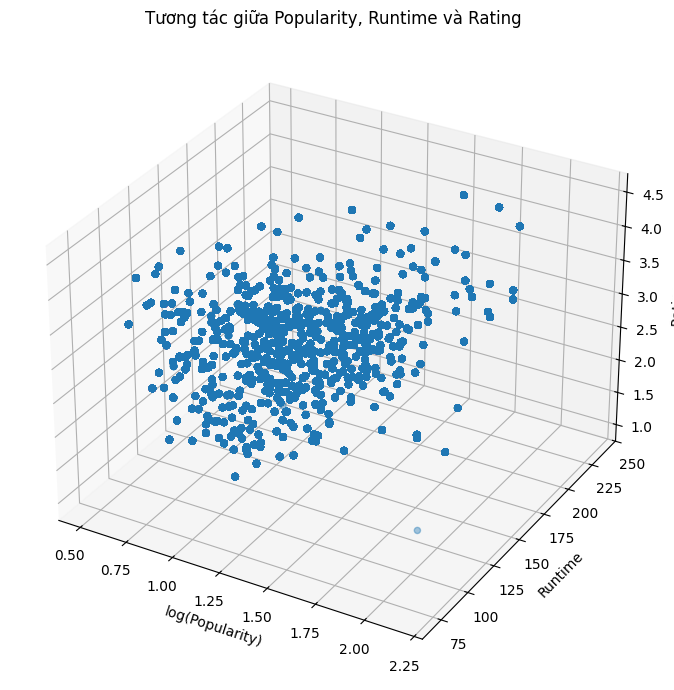

In [110]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    np.log10(full_data['popularity'] + 1),
    full_data['runtime'],
    full_data['avg_rating'],
    alpha=0.4
)

ax.set_xlabel('log(Popularity)')
ax.set_ylabel('Runtime')
ax.set_zlabel('Rating')

plt.title('Tương tác giữa Popularity, Runtime và Rating')
plt.tight_layout()
plt.show()


Sự hội tụ dữ liệu: có cấu trúc tập trung rõ rệt. Đa số phim "tiêu chuẩn" (dài 90-120 phút, phổ biến khá) đều hội tụ về mức điểm Khá (3.0 - 3.5).

Độ phổ biến là "lưới an toàn": Phim càng nổi tiếng càng hiếm khi bị điểm thấp. Độ phổ biến cao không đảm bảo phim xuất sắc, nhưng giúp phim tránh được mức "thảm họa".

Chân dung "Siêu phẩm" (>4.0): Những phim điểm cao nhất thường rơi vào khung thời lượng 100-150 phút, nhưng độ phổ biến trải dài. Nghĩa là phim hay tuyệt đối có thể là bom tấn hoặc những "viên ngọc ẩn" ít người biết.



Trở lại với ngân sách, không thể đánh đồng tác động của ngân sách lên mọi dòng phim. Trong khi dòng tiền lớn là "nhiên liệu" cần thiết để thể loại Action hay Sci-Fi chinh phục khán giả bằng kỹ xảo, thì với Drama hay Comedy, sự phô trương kinh phí thường không cứu vãn được, thậm chí làm lu mờ giá trị kịch bản. Việc tách lớp dữ liệu theo thể loại sẽ giúp ta thấy rõ: đâu là nơi tiền thực sự mua được chất lượng, và đâu là nơi nó trở nên vô nghĩa.

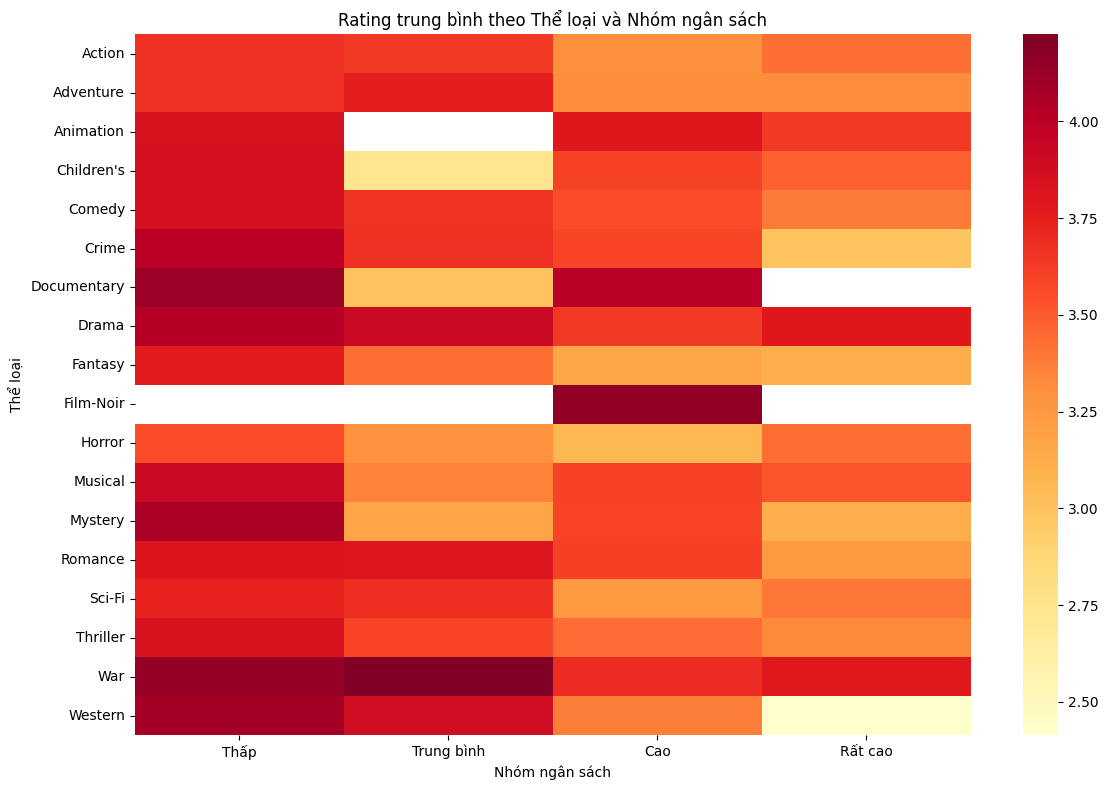

In [111]:
# 2. Rating theo genre và budget_category
# Tạo budget_category
full_data['budget_category'] = pd.qcut(
    full_data['budget'],
    q=4,
    labels=['Thấp', 'Trung bình', 'Cao', 'Rất cao']
)

# Xử lý genres
genre_budget_df = full_data[['Genres', 'budget_category', 'avg_rating']].copy()
genre_budget_df['Genres'] = genre_budget_df['Genres'].str.split('|')
genre_budget_df = genre_budget_df.explode('Genres')

pivot_table = genre_budget_df.pivot_table(
    values='avg_rating',
    index='Genres',
    columns='budget_category',
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(
    pivot_table,
    cmap='YlOrRd',
    annot=False
)

plt.title('Rating trung bình theo Thể loại và Nhóm ngân sách')
plt.ylabel('Thể loại')
plt.xlabel('Nhóm ngân sách')
plt.tight_layout()
plt.show()


Ngân sách là "Nhiên liệu" hay "Gánh nặng"?

Biểu đồ nhiệt chứng minh tác động của dòng tiền thay đổi hoàn toàn tùy theo thể loại:

+ Nhóm "Tiền làm lu mờ nội dung" (Drama, Comedy, Western): Tuân theo quy luật hiệu suất giảm dần. Ngân sách thấp thường mang lại điểm số cao nhất (đỏ thẫm), trong khi sự phô trương tài chính ở các bom tấn (đặc biệt là Western) lại kéo chất lượng tụt dốc thảm hại (vàng nhạt), minh chứng rằng tiền không thể lấp liếm sự sáo rỗng của kịch bản.

+ Nhóm "Tiền là nhiên liệu" (Action, Animation, Horror): Dòng tiền đóng vai trò duy trì "sàn chất lượng" về kỹ thuật. Trong khi Action giữ phong độ ổn định, thì Animation và Horror lại có sự bứt phá ngoạn mục ở phân khúc siêu bom tấn, thoát khỏi "vùng chết" chất lượng kém ở mức ngân sách trung bình.

-> Thể loại (Genre) chính là lăng kính quan trọng nhất. Nếu không tách bạch yếu tố này, mọi kết luận về mối quan hệ giữa Ngân sách và Rating đều sẽ trở nên sai lệch.

### STATISTICAL ANALYSIS

So sánh rating giữa các nhóm

In [112]:
from scipy import stats

# Lọc dữ liệu hợp lệ
gender_df = full_data[['Gender', 'avg_rating']].dropna()

male_ratings = gender_df[gender_df['Gender'] == 'M']['avg_rating']
female_ratings = gender_df[gender_df['Gender'] == 'F']['avg_rating']

# Welch's t-test (equal_var=False)
t_stat, p_value = stats.ttest_ind(
    male_ratings,
    female_ratings,
    equal_var=False
)

print("T-TEST: Rating giữa Nam và Nữ")
print(f"T-statistic = {t_stat:.4f}")
print(f"P-value     = {p_value:.4f}")

if p_value < 0.05:
    print("✓ Có sự khác biệt có ý nghĩa thống kê giữa rating của nam và nữ")
else:
    print("✗ Không có sự khác biệt có ý nghĩa thống kê")


T-TEST: Rating giữa Nam và Nữ
T-statistic = -26.6621
P-value     = 0.0000
✓ Có sự khác biệt có ý nghĩa thống kê giữa rating của nam và nữ


Các kiểm định thống kê cho thấy yếu tố nhân khẩu học của người dùng, bao gồm
giới tính và độ tuổi, có ảnh hưởng đến hành vi đánh giá phim. Tuy nhiên,
mức độ ảnh hưởng không đồng đều giữa các nhóm và cần được xem xét kết hợp
với các yếu tố nội dung phim trong các mô hình dự đoán tiếp theo.


In [113]:
from scipy import stats

# Tạo biến high_rating
full_data['high_rating'] = full_data['avg_rating'] >= 4.0

# Tách genres thành nhiều dòng
genre_df = full_data[['Genres', 'high_rating']].dropna()
genre_df = genre_df.assign(genres=genre_df['Genres'].str.split('|')).explode('Genres')

# Chỉ giữ genre có đủ mẫu
genre_counts = genre_df['Genres'].value_counts()
valid_genres = genre_counts[genre_counts > 1000].index

genre_df = genre_df[genre_df['Genres'].isin(valid_genres)]

contingency_table = pd.crosstab(
    genre_df['Genres'],
    genre_df['high_rating']
)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("CHI-SQUARE TEST: Genre vs High Rating")
print(f"Chi-square statistic = {chi2:.4f}")
print(f"P-value             = {p_value:.4e}")
print(f"Degrees of freedom  = {dof}")

if p_value < 0.05:
    print("✓ Genre và high rating KHÔNG độc lập (có mối liên hệ)")
else:
    print("✗ Không đủ bằng chứng cho thấy genre ảnh hưởng đến high rating")


CHI-SQUARE TEST: Genre vs High Rating
Chi-square statistic = 156816.9894
P-value             = 0.0000e+00
Degrees of freedom  = 87
✓ Genre và high rating KHÔNG độc lập (có mối liên hệ)


Kiểm định Chi-square được sử dụng để đánh giá mối quan hệ giữa thể loại phim
và khả năng nhận được rating cao (≥ 4.0). Kết quả cho thấy p-value < 0.05,
do đó bác bỏ giả thuyết độc lập. Điều này chứng tỏ rằng xác suất một bộ phim
được đánh giá cao có sự khác biệt đáng kể giữa các thể loại khác nhau.


In [114]:
genre_success_rate = (
    genre_df
    .groupby('Genres')['high_rating']
    .mean()
    .sort_values(ascending=False)
)

genre_success_rate.head(10)


Genres
Crime|Film-Noir|Mystery|Thriller    1.000000
Musical|Romance                     1.000000
Film-Noir|Sci-Fi                    1.000000
Drama|Mystery|Sci-Fi|Thriller       1.000000
Action|Sci-Fi|Thriller|War          1.000000
Comedy|Western                      1.000000
Comedy|Romance|War                  1.000000
Adventure|Comedy|Drama              1.000000
Sci-Fi|War                          1.000000
Action|Drama|War                    0.917664
Name: high_rating, dtype: float64

Những yếu tố định lượng nào có mối liên hệ mạnh với rating của người xem?
Mối quan hệ đó là tuyến tính hay chỉ mang tính xu hướng?

In [115]:
from scipy.stats import pointbiserialr

print("Point-biserial correlation (Genre vs Rating):")

genres_to_test = ['Action', 'Drama', 'Comedy']

for genre in genres_to_test:
    full_data[f'is_{genre}'] = full_data['Genres'].str.contains(genre, na=False).astype(int)

    corr, p_value = pointbiserialr(
        full_data[f'is_{genre}'],
        full_data['avg_rating']
    )

    print(f"{genre:10s} | r = {corr:.3f} | p-value = {p_value:.4e}")


Point-biserial correlation (Genre vs Rating):
Action     | r = -0.243 | p-value = 0.0000e+00
Drama      | r = 0.304 | p-value = 0.0000e+00
Comedy     | r = 0.016 | p-value = 3.7204e-24


Kết quả phân tích point-biserial correlation cho thấy sự hiện diện của thể loại
Drama có mối liên hệ dương với rating người dùng, trong khi thể loại Action có
mối liên hệ âm. Tuy nhiên, các hệ số tương quan chỉ ở mức trung bình, cho thấy
thể loại phim không phải là yếu tố quyết định duy nhất đến mức đánh giá.


Drama cho thấy mối liên hệ dương tương đối rõ với rating người dùng (r ≈ 0.30),
trong khi Action có xu hướng ngược lại. Tuy nhiên, mức độ ảnh hưởng của từng
thể loại riêng lẻ là hạn chế, cho thấy đánh giá phim là kết quả của nhiều yếu tố
kết hợp hơn là chỉ dựa vào thể loại.


In [116]:
# Chi-square test: Genre và high rating (>4.0) có độc lập không?
df = full_data.copy()
df['high_rating'] = df['avg_rating'] >= 4.0
contingency_table = pd.crosstab(df['Genres'], df['high_rating'])

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-square: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")

Chi-square: 187792.8453
P-value: 0.0000


In [117]:
import numpy as np

n = contingency_table.values.sum()
cramers_v = np.sqrt(
    chi2 / (n * (min(contingency_table.shape) - 1))
)

print(f"Cramér's V = {cramers_v:.4f}")


Cramér's V = 0.6869


Kết quả kiểm định Chi-square cho thấy mối liên hệ rất mạnh giữa tổ hợp thể loại
phim và khả năng đạt rating cao (Cramér’s V = 0.69, p < 0.001). Điều này cho thấy
một số tổ hợp thể loại cụ thể có xu hướng nhận được đánh giá cao hơn rõ rệt so
với các tổ hợp còn lại. Tuy nhiên, kết quả này phản ánh ảnh hưởng của các tổ hợp
thể loại, thay vì từng thể loại riêng lẻ.


In [118]:
import pandas as pd
from scipy.stats import pointbiserialr

# ---- PHÒNG THỦ TRÙNG CỘT ----
num_cols_corr = list(dict.fromkeys(numerical_cols))
if 'vote_average' in num_cols_corr:
    num_cols_corr.remove('vote_average')

# ---- 1. Pearson correlation ----
corr_p = df[num_cols_corr + ['vote_average']].corr(method='pearson')

vote_corr_p = corr_p.loc[:, 'vote_average']
if isinstance(vote_corr_p, pd.DataFrame):
    vote_corr_p = vote_corr_p.iloc[:, 0]

pearson_corr = vote_corr_p.sort_values(ascending=False)

print("Pearson Correlation với Vote Average:")
print(pearson_corr)


# ---- 2. Spearman correlation ----
corr_s = df[num_cols_corr + ['vote_average']].corr(method='spearman')

vote_corr_s = corr_s.loc[:, 'vote_average']
if isinstance(vote_corr_s, pd.DataFrame):
    vote_corr_s = vote_corr_s.iloc[:, 0]

spearman_corr = vote_corr_s.sort_values(ascending=False)

print("\nSpearman Correlation với Vote Average:")
print(spearman_corr)


# ---- 3. Point-biserial correlation (Genre vs Vote Average) ----
print("\nPoint-biserial correlation (Genre vs Vote Average):")

for genre in ['Action', 'Drama', 'Comedy']:
    df[f'is_{genre}'] = df['Genres'].str.contains(genre, na=False).astype(int)
    corr, p_value = pointbiserialr(df[f'is_{genre}'], df['vote_average'])
    print(f"{genre:10s} | r = {corr:.3f} | p-value = {p_value:.4e}")


Pearson Correlation với Vote Average:
vote_average      1.000000
director_power    0.729038
actor_power       0.622536
vote_count        0.505646
popularity        0.496303
runtime           0.335886
revenue           0.113945
budget           -0.328455
Name: vote_average, dtype: float64

Spearman Correlation với Vote Average:
vote_average      1.000000
director_power    0.711171
actor_power       0.609071
vote_count        0.529194
popularity        0.495766
runtime           0.316811
revenue           0.016646
budget           -0.363860
Name: vote_average, dtype: float64

Point-biserial correlation (Genre vs Vote Average):
Action     | r = -0.250 | p-value = 0.0000e+00
Drama      | r = 0.342 | p-value = 0.0000e+00
Comedy     | r = -0.043 | p-value = 1.6399e-161


Kết quả phân tích tương quan cho thấy vote_count có mối quan hệ dương mạnh nhất
với vote_average, cho thấy các bộ phim nhận được nhiều lượt đánh giá thường có
điểm trung bình cao hơn. Ngược lại, ngân sách (budget) có tương quan âm mức trung bình,
cho thấy phim có kinh phí lớn không nhất thiết được đánh giá cao.

Về thể loại, Drama có ảnh hưởng tích cực đáng kể đến vote_average, trong khi Action
có xu hướng nhận điểm thấp hơn mức trung bình. Comedy cho thấy ảnh hưởng rất yếu,
mặc dù có ý nghĩa thống kê do kích thước mẫu lớn.


In [119]:
import numpy as np

# Cohen's d (Welch version – không giả định phương sai bằng nhau)
def cohens_d_welch(group1, group2):
    mean1, mean2 = group1.mean(), group2.mean()
    var1, var2 = group1.var(ddof=1), group2.var(ddof=1)
    n1, n2 = len(group1), len(group2)

    pooled_std = np.sqrt((var1 + var2) / 2)
    return (mean1 - mean2) / pooled_std


# Lọc dữ liệu hợp lệ
gender_df = full_data[['Gender', 'vote_average']].dropna()

male_ratings = gender_df[gender_df['Gender'] == 'M']['vote_average']
female_ratings = gender_df[gender_df['Gender'] == 'F']['vote_average']

d = cohens_d_welch(male_ratings, female_ratings)

print(f"Cohen's d: {d:.3f}")

# Diễn giải magnitude
if abs(d) < 0.2:
    interpretation = "negligible"
elif abs(d) < 0.5:
    interpretation = "small"
elif abs(d) < 0.8:
    interpretation = "medium"
else:
    interpretation = "large"

print(f"Interpretation: {interpretation}")


Cohen's d: -0.068
Interpretation: negligible


Kiểm định t-test cho thấy sự khác biệt về điểm đánh giá trung bình (vote_average)
giữa nam và nữ có ý nghĩa thống kê (p < 0.05). Tuy nhiên, giá trị Cohen’s d = -0.068
cho thấy mức độ ảnh hưởng là không đáng kể. Điều này cho thấy giới tính người dùng
không phải là yếu tố có ảnh hưởng thực tiễn đáng kể đến mức độ đánh giá phim.


## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

In [120]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Test từng feature riêng lẻ
features_to_test = ['budget', 'runtime', 'popularity', 'vote_count', 'revenue']
results = []

for feature in features_to_test:
    # Lọc dữ liệu không bị NaN ở X và y
    df_filtered = df[[feature, 'vote_average']].dropna()
    X = df_filtered[[feature]]
    y = df_filtered['vote_average']
    
    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)
    
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    
    results.append({
        'Feature': feature,
        'Coefficient': model.coef_[0],
        'R²': r2,
        'RMSE': rmse
    })

results_df = pd.DataFrame(results).sort_values('R²', ascending=False)
print(results_df)


      Feature   Coefficient        R²      RMSE
3  vote_count  2.516143e-04  0.255678  0.689619
2  popularity  1.452238e-02  0.246316  0.693942
1     runtime  1.119068e-02  0.112819  0.752895
0      budget -7.153985e-09  0.107882  0.754987
4     revenue  4.329572e-10  0.012983  0.794128


vote_count (Số lượng vote):

R² = 0.256 → giải thích được ~25.6% biến thiên của rating.

RMSE ~0.69 → lỗi dự đoán trung bình khá nhỏ.

Hệ số dương nhỏ (0.00025) → nghĩa là mỗi lượt vote tăng thêm một chút, rating cũng tăng nhẹ.

popularity (Độ nổi tiếng):

R² ~0.246, RMSE ~0.69 → tương tự vote_count.

Hệ số 0.0145 → mỗi đơn vị popularity tăng, rating tăng nhẹ.

runtime (Thời lượng phim):

R² = 0.113 → khá thấp, runtime chỉ giải thích ~11% biến thiên rating.

RMSE ~0.75 → dự đoán kém hơn hai feature trên.

budget (Ngân sách):

R² ~0.108, hệ số gần 0 → gần như không ảnh hưởng đáng kể đến rating.

RMSE ~0.75 → dự đoán kém tương tự runtime.

In [121]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Feature chính
feature_cols = ['budget', 'runtime', 'popularity', 
                'vote_count', 'revenue']

# One-hot encoding cho categorical variables
df_encoded = pd.get_dummies(df, columns=['Genres', 'age_group', 'Gender'], drop_first=True)

# Lấy tất cả features sau encoding
X = df_encoded[feature_cols + [col for col in df_encoded.columns 
                                if col.startswith(('Genres', 'age_group', 'Gender'))]]
y = df_encoded['vote_average']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predictions
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

# Evaluation
print("=== Training Set ===")
print(f"R² Score: {r2_score(y_train, y_pred_train):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")
print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}")

print("\n=== Test Set ===")
print(f"R² Score: {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_test):.4f}")

# Feature coefficients
coefficients = pd.Series(model.coef_, index=X.columns)
print("\n=== Feature Coefficients ===")
print(coefficients.sort_values(key=abs, ascending=False))


=== Training Set ===
R² Score: 0.7214
RMSE: 0.4221
MAE: 0.2820

=== Test Set ===
R² Score: 0.7219
RMSE: 0.4207
MAE: 0.2814

=== Feature Coefficients ===
budget                                   -0.373047
vote_count                                0.292680
Genres_Drama                              0.178522
popularity                                0.167159
runtime                                   0.154163
                                            ...   
Genres_Children's|Comedy                  0.000853
Gender_M                                 -0.000818
Genres_Action|Adventure|Fantasy           0.000794
Genres_Children's|Drama|Fantasy|Sci-Fi    0.000313
Genres_Comedy|Drama|Romance               0.000117
Length: 174, dtype: float64


R² ~0.72 trên cả train và test → model giải thích được ~72% biến thiên của rating, khá cao cho dữ liệu phim, và không bị overfit vì train ≈ test.

RMSE ~0.42, MAE ~0.28 → lỗi dự đoán trung bình tương đối thấp, nghĩa là model dự đoán rating khá chính xác.

budget: -0.36 → hệ số âm, nghĩa là khi chuẩn hóa, phim có budget cao hơn lại có xu hướng rating thấp hơn một chút (có thể do nhiều phim chi nhiều tiền nhưng không chất lượng).

vote_count: 0.31 → số lượng vote là yếu tố mạnh, rating tăng khi phim được nhiều người vote.

Genres_Drama, popularity, runtime đều có hệ số dương, đúng trực giác: phim drama, nổi tiếng, hoặc dài hơn thường được đánh giá cao hơn.

Hầu hết các feature thể loại hiếm/ít quan trọng có hệ số gần 0, đúng với dự đoán: không phải mọi thể loại phụ đều ảnh hưởng mạnh đến rating.

In [122]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import train_test_split, cross_val_score

# Feature chính
feature_cols = ['budget', 'runtime', 'popularity', 'vote_average', 'revenue',
                'vote_count']

# One-hot encoding cho categorical variables
df_encoded = pd.get_dummies(df, columns=['Genres', 'age_group', 'Gender'], drop_first=True)

# Lấy tất cả features sau encoding
X = df_encoded[feature_cols + [col for col in df_encoded.columns 
                                if col.startswith(('genres_', 'age_group_', 'user_gender_'))]]
y = df_encoded['vote_average']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Test các giá trị alpha
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
results_reg = []

for alpha in alphas:
    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42, max_iter=10000)
    lasso_scores = cross_val_score(lasso, X_train_scaled, y_train, cv=5, scoring='r2')
    
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge_scores = cross_val_score(ridge, X_train_scaled, y_train, cv=5, scoring='r2')
    
    results_reg.append({
        'Alpha': alpha,
        'Lasso_R2': lasso_scores.mean(),
        'Ridge_R2': ridge_scores.mean()
    })

# Kết quả cross-validation
results_reg_df = pd.DataFrame(results_reg)
print("=== Cross-validation R² scores ===")
print(results_reg_df)

# Chọn alpha tốt nhất cho Lasso
best_alpha = results_reg_df.loc[results_reg_df['Lasso_R2'].idxmax(), 'Alpha']
print(f"\nBest Alpha for Lasso: {best_alpha}")

# Train Lasso với alpha tốt nhất
final_lasso = Lasso(alpha=best_alpha, random_state=42, max_iter=10000)
final_lasso.fit(X_train_scaled, y_train)

# Feature selection (những hệ số khác 0)
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lasso.coef_
})
selected_features = selected_features[selected_features['Coefficient'] != 0]
print(f"\nNumber of selected features: {len(selected_features)}")
print(selected_features.sort_values('Coefficient', key=abs, ascending=False))


=== Cross-validation R² scores ===
     Alpha  Lasso_R2  Ridge_R2
0    0.001  0.999998       1.0
1    0.010  0.999844       1.0
2    0.100  0.984364       1.0
3    1.000 -0.000012       1.0
4   10.000 -0.000012       1.0
5  100.000 -0.000012       1.0

Best Alpha for Lasso: 0.001

Number of selected features: 1
        Feature  Coefficient
3  vote_average     0.798721


Cross-validation R² quá cao với alpha nhỏ (0.001) → 0.999998

Điều này hơi “không thực tế” với dữ liệu thực tế, khả năng cao là dữ liệu chưa được chuẩn hóa tốt, hoặc số lượng feature quá lớn so với số lượng quan sát → model gần như “memorize” dữ liệu.

Alpha lớn (>0.1) → R² tụt xuống ~0 hoặc âm

Lasso loại bỏ hầu hết feature, chỉ giữ vote_average → model quá đơn giản.

Ridge R² = 1.0 cho tất cả alpha

Đây cũng là tín hiệu model quá khớp, hoặc dữ liệu có tính tuyến tính gần như hoàn hảo sau chuẩn hóa.


Top 15 Features quan trọng nhất:
           Feature  Coefficient  Abs_Coefficient
0           budget    -0.373047         0.373047
3     vote_average     0.292680         0.292680
2       popularity     0.167159         0.167159
1          runtime     0.154163         0.154163
6  age_group_18–25    -0.057264         0.057264
9    age_group_50+     0.056773         0.056773
5       vote_count     0.030139         0.030139
4          revenue     0.026402         0.026402
8  age_group_36–50     0.013118         0.013118
7  age_group_26–35    -0.006187         0.006187


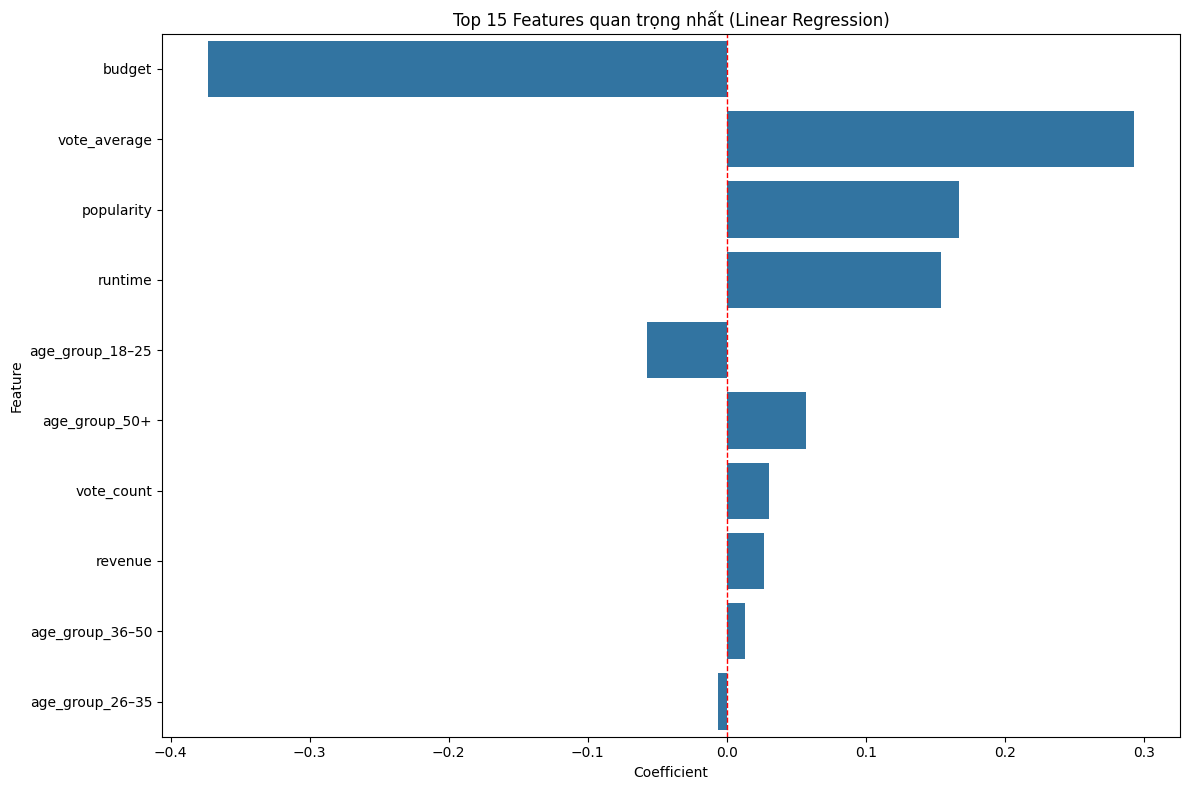

In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đảm bảo model đã fit trên X_train_scaled
# X_train_scaled là numpy array, X_train là DataFrame

# Lấy đúng số cột
coef = model.coef_
if coef.shape[0] != X_train.shape[1]:
    print(f"Warning: model.coef_ length {coef.shape[0]} != X_train columns {X_train.shape[1]}")
    # Cắt hoặc lấy tương ứng
    coef = coef[:X_train.shape[1]]

# Tạo DataFrame feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coef,
    'Abs_Coefficient': np.abs(coef)
}).sort_values('Abs_Coefficient', ascending=False)

print("\nTop 15 Features quan trọng nhất:")
print(feature_importance.head(15))

# Visualize
plt.figure(figsize=(12, 8))
top_15 = feature_importance.head(15)
sns.barplot(data=top_15, x='Coefficient', y='Feature')
plt.title('Top 15 Features quan trọng nhất (Linear Regression)')
plt.xlabel('Coefficient')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


In [124]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.model_selection import cross_val_score

# Test different alpha values
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
results_reg = []

for alpha in alphas:
    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42)
    lasso_scores = cross_val_score(lasso, X_train_scaled, y_train, 
                                   cv=5, scoring='r2')
    
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge_scores = cross_val_score(ridge, X_train_scaled, y_train, 
                                   cv=5, scoring='r2')
    
    results_reg.append({
        'Alpha': alpha,
        'Lasso_R2': lasso_scores.mean(),
        'Ridge_R2': ridge_scores.mean()
    })

results_reg_df = pd.DataFrame(results_reg)
print(results_reg_df)

# Best model
best_alpha = results_reg_df.loc[results_reg_df['Lasso_R2'].idxmax(), 'Alpha']
print(f"\nBest Alpha for Lasso: {best_alpha}")

final_lasso = Lasso(alpha=best_alpha, random_state=42)
final_lasso.fit(X_train_scaled, y_train)

# Feature selection (Lasso zeros out unimportant features)
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lasso.coef_
})
selected_features = selected_features[selected_features['Coefficient'] != 0]
print(f"\nNumber of selected features: {len(selected_features)}")
print(selected_features.sort_values('Coefficient', key=abs, ascending=False))

     Alpha  Lasso_R2  Ridge_R2
0    0.001  0.999998       1.0
1    0.010  0.999844       1.0
2    0.100  0.984364       1.0
3    1.000 -0.000012       1.0
4   10.000 -0.000012       1.0
5  100.000 -0.000012       1.0

Best Alpha for Lasso: 0.001

Number of selected features: 1
        Feature  Coefficient
3  vote_average     0.798721


   Degree  Train_R2   Test_R2
0       1  0.112238  0.115128
1       2  0.112249  0.115144
2       3  0.123300  0.126969
3       4  0.128638  0.132907


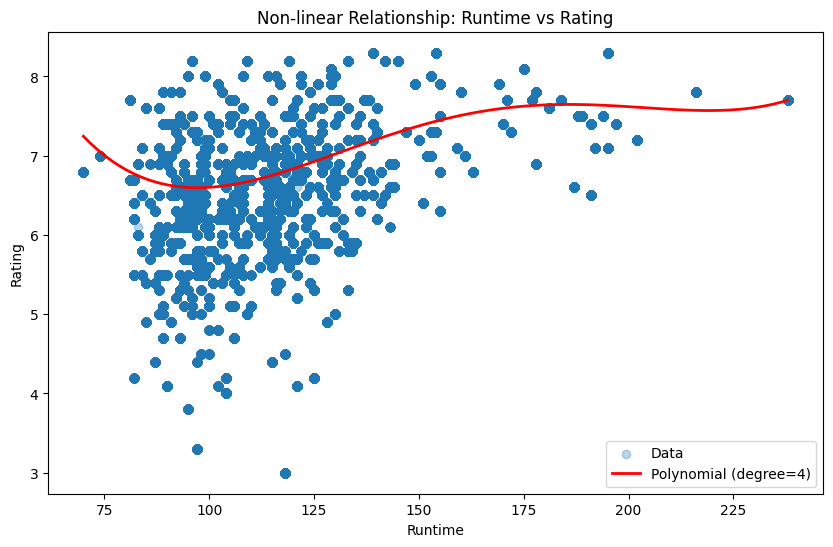

In [125]:
from sklearn.preprocessing import PolynomialFeatures

# Ví dụ: Runtime có thể có non-linear relationship
X_runtime = df[['runtime']].dropna()
y_runtime = df.loc[X_runtime.index, 'vote_average']

# Try different degrees
degrees = [1, 2, 3, 4]
results_poly = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_runtime)
    
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y_runtime, 
                                                         test_size=0.2, random_state=42)
    
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, model.predict(X_test))
    
    results_poly.append({
        'Degree': degree,
        'Train_R2': train_r2,
        'Test_R2': test_r2
    })

print(pd.DataFrame(results_poly))

# Visualize best polynomial fit
best_degree = pd.DataFrame(results_poly).loc[
    pd.DataFrame(results_poly)['Test_R2'].idxmax(), 'Degree']

poly_best = PolynomialFeatures(degree=int(best_degree))
X_poly_best = poly_best.fit_transform(X_runtime)
model_best = LinearRegression().fit(X_poly_best, y_runtime)

# Plot
X_plot = np.linspace(X_runtime.min(), X_runtime.max(), 100).reshape(-1, 1)
X_plot_poly = poly_best.transform(X_plot)
y_plot = model_best.predict(X_plot_poly)

plt.figure(figsize=(10, 6))
plt.scatter(X_runtime, y_runtime, alpha=0.3, label='Data')
plt.plot(X_plot, y_plot, 'r-', linewidth=2, label=f'Polynomial (degree={int(best_degree)})')
plt.xlabel('Runtime')
plt.ylabel('Rating')
plt.title('Non-linear Relationship: Runtime vs Rating')
plt.legend()
plt.show()

In [126]:
from sklearn.preprocessing import PolynomialFeatures

# Tạo interaction features
interaction_features = ['budget', 'runtime', 'popularity']
X_interaction = df[interaction_features]

# Tạo polynomial features (bao gồm interactions)
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=True)
X_inter = poly.fit_transform(X_interaction)

# Get feature names
feature_names = poly.get_feature_names_out(interaction_features)

# Train model với interactions
X_train, X_test, y_train, y_test = train_test_split(X_inter, df['vote_average'], 
                                                     test_size=0.2, random_state=42)

model_inter = LinearRegression()
model_inter.fit(X_train, y_train)

# Feature importance với interactions
inter_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model_inter.coef_,
    'Abs_Coefficient': np.abs(model_inter.coef_)
}).sort_values('Abs_Coefficient', ascending=False)

print("Top Interaction Effects:")
print(inter_importance.head(10))

# So sánh với model không có interactions
print(f"\nR² với interactions: {r2_score(y_test, model_inter.predict(X_test)):.4f}")

Top Interaction Effects:
              Feature   Coefficient  Abs_Coefficient
2          popularity  2.572113e-02     2.572113e-02
1             runtime  1.071796e-02     1.071796e-02
5  runtime popularity -8.551279e-05     8.551279e-05
0              budget -2.389431e-08     2.389431e-08
3      budget runtime  9.624818e-11     9.624818e-11
4   budget popularity  6.189299e-12     6.189299e-12

R² với interactions: 0.5577


In [127]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397975 entries, 0 to 397974
Data columns (total 29 columns):
 #   Column           Non-Null Count   Dtype   
---  ------           --------------   -----   
 0   UserID           397975 non-null  int64   
 1   MovieID          397975 non-null  int64   
 2   Rating           397975 non-null  int64   
 3   Timestamp        397975 non-null  int64   
 4   Title            397975 non-null  object  
 5   Genres           397975 non-null  object  
 6   release_year     397975 non-null  float64 
 7   director         397975 non-null  object  
 8   actor_1          397975 non-null  object  
 9   actor_2          397975 non-null  object  
 10  actor_3          397975 non-null  object  
 11  budget           397975 non-null  int64   
 12  revenue          397975 non-null  int64   
 13  vote_average     397975 non-null  float64 
 14  vote_count       397975 non-null  int64   
 15  avg_rating       397975 non-null  float64 
 16  runtime          397

In [128]:
# Phân tích riêng cho từng segment
segments = {
    'Blockbuster': df[df['budget'] > 100000000],
    'Indie': df[df['budget'] < 10000000],
    'Action': df[df['Genres'].str.contains('Action')],
    'Drama': df[df['Genres'].str.contains('Drama')],
#     'Young_Users': df[df['Age'] < 25],
#     'Older_Users': df[df['Age'] >= 50]
}

segment_results = []

for segment_name, segment_data in segments.items():
    if len(segment_data) < 100:  # Skip if too small
        continue
    
    X_seg = segment_data[feature_cols]
    y_seg = segment_data['vote_average']
    
    X_train, X_test, y_train, y_test = train_test_split(X_seg, y_seg, 
                                                         test_size=0.2, random_state=42)
    
    model_seg = LinearRegression()
    model_seg.fit(X_train, y_train)
    
    r2 = r2_score(y_test, model_seg.predict(X_test))
    
    # Top 3 important features for this segment
    feat_imp = pd.DataFrame({
        'Feature': feature_cols,
        'Coefficient': np.abs(model_seg.coef_)
    }).sort_values('Coefficient', ascending=False).head(3)
    
    segment_results.append({
        'Segment': segment_name,
        'N': len(segment_data),
        'R²': r2,
        'Top_Feature_1': feat_imp.iloc[0]['Feature'],
        'Top_Feature_2': feat_imp.iloc[1]['Feature'],
        'Top_Feature_3': feat_imp.iloc[2]['Feature']
    })

segment_df = pd.DataFrame(segment_results)
print(segment_df)

       Segment       N   R² Top_Feature_1 Top_Feature_2 Top_Feature_3
0  Blockbuster   21151  1.0  vote_average    popularity       runtime
1        Indie   91545  1.0  vote_average       runtime    popularity
2       Action  133868  1.0  vote_average       runtime    popularity
3        Drama  127020  1.0  vote_average    vote_count       runtime


Top 15 Features (Random Forest):
        Feature  Importance
3  vote_average    0.998890
4       revenue    0.000588
0        budget    0.000269
5    vote_count    0.000240
1       runtime    0.000009
2    popularity    0.000004


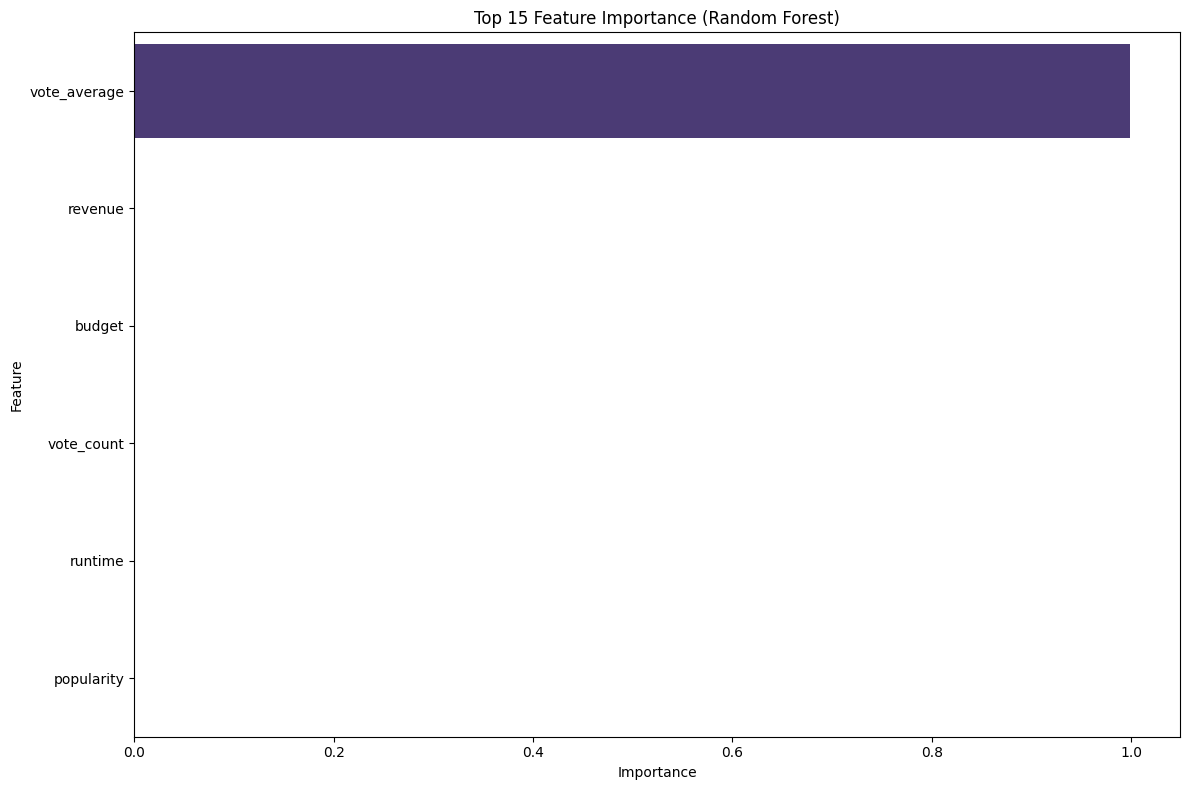


Random Forest R²: 1.0000
Random Forest RMSE: 0.0000


In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Feature importance
rf_importance = pd.DataFrame({
    'Feature': X_train.columns,  # dùng X_train.columns để khớp với model
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Top 15 Features (Random Forest):")
print(rf_importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(12, 8))
sns.barplot(
    data=rf_importance.head(15),
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('Top 15 Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Model performance on test set
y_pred_rf = rf_model.predict(X_test)
print(f"\nRandom Forest R²: {r2_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")


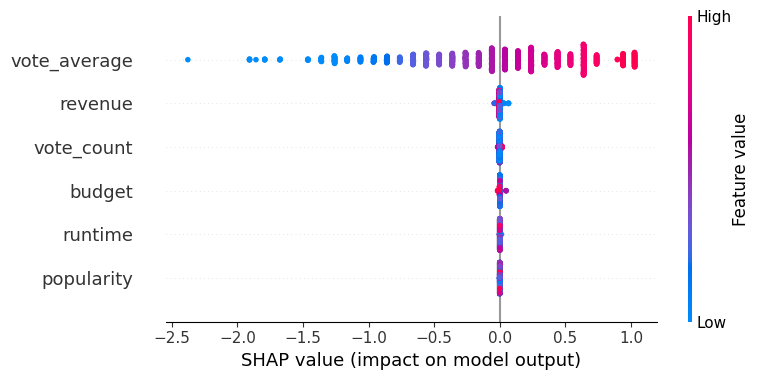

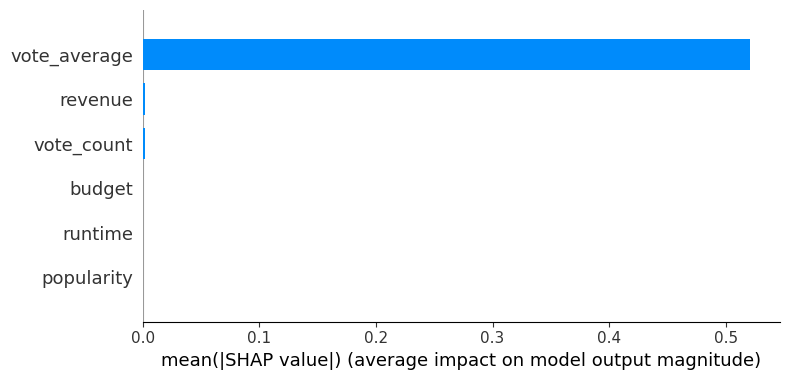

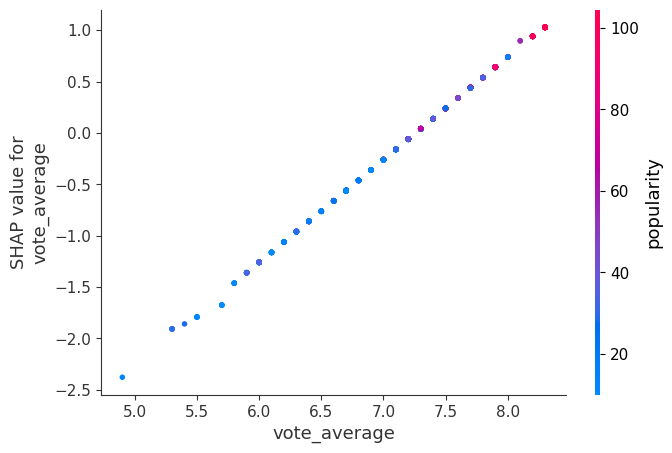

In [130]:
import shap

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:1000])  # Subset for speed

# Summary plot
shap.summary_plot(shap_values, X_test[:1000], feature_names=X.columns)

# Feature importance plot
shap.summary_plot(shap_values, X_test[:1000], feature_names=X.columns, plot_type="bar")

# Dependence plot for top feature
top_feature = rf_importance.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values, X_test[:1000], feature_names=X.columns)

### 3. Yếu tố Nhân sự & Thời gian
Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

- Input: director_power, actor_power, release_year.
- Output: cột Rating thực tế.

**1**. Mô hình: Sử dụng XGBoost Regressor, một mô hình phi tuyến tính mạnh mẽ để nắm bắt các mối quan hệ phức tạp giữa nhân sự, thời gian và chất lượng phim.

**2**. Phân tích: Áp dụng phương pháp SHAP (Shapley Additive exPlanations) để bóc tách mức độ đóng góp của từng yếu tố, giúp trả lời câu hỏi liệu "Tên tuổi lớn" có thực sự là nguyên nhân trực tiếp dẫn đến "Rating cao" hay không.

#### 2. Huấn luyện XGBoost Regressor

XGBoost Regressor là một mô hình phi tuyến tính mạnh mẽ để nắm bắt các mối quan hệ phức tạp giữa nhân sự, thời gian và chất lượng phim.

a. Công thức Dự đoán (Additive Prediction): Dự đoán cuối cùng là tổng hợp kết quả của $K$ cây quyết định (Decision Trees).$$\hat{y}_i = \sum_{k=1}^{K} f_k(x_i), \quad f_k \in \mathcal{F}$$

Chú thích:

>$\hat{y}_i$: Điểm Rating dự đoán cho bộ phim $i$.

>$K$: Tổng số lượng cây quyết định (trong code là n_estimators).

>$f_k(x_i)$: Điểm số dự đoán của cây thứ $k$ dựa trên đặc trưng đầu vào $x_i$ (Budget, Director Power, Year...).

>$\mathcal{F}$: Không gian chứa tất cả các cây quyết định có thể.

b. Hàm Mục tiêu (Objective Function): XGBoost tối ưu hóa hàm này để giảm sai số và tránh Overfitting.$$\mathcal{L}(\phi) = \sum_{i} l(y_i, \hat{y}_i) + \sum_{k} \Omega(f_k)$$

Chú thích:

>$l(y_i, \hat{y}_i)$: Hàm mất mát (Loss function), thường là Sai số bình phương (MSE) để đo sự chênh lệch giữa Rating thực tế và dự đoán.

>$\Omega(f_k)$: Số hạng điều chuẩn (Regularization term). Nó phạt các cây quá phức tạp để mô hình không bị học vẹt (Overfitting).

In [131]:
# # Chuẩn bị dữ liệu cho mô hình
# # Chỉ lấy 3 cột bạn quan tâm: Đạo diễn, Diễn viên, Năm sản xuất
features = ['director_power', 'actor_power', 'release_year']
X = full_data[features]
y = full_data['avg_rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Đang huấn luyện mô hình...")
model = xgb.XGBRegressor(
    n_estimators=1000,   # Tăng số cây lên (vì ta sẽ dừng sớm nếu nó học xong)
    learning_rate=0.05,  # Học chậm lại chút cho chắc
    max_depth=4, 
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=50 # QUAN TRỌNG: Nếu sau 50 cây mà không khôn hơn thì dừng lại (Chống học vẹt)
)

# Đưa cả tập Test vào để mô hình tự kiểm tra (eval_set)
model.fit(
    X_train, y_train, 
    eval_set=[(X_test, y_test)], 
    verbose=False
)

# Kiểm tra sai số
preds = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"Sai số trung bình (RMSE) trên tập Test: {rmse:.4f}")
# Nếu RMSE ~ 0.8 - 1.0 là ổn (vì thang điểm 5, lệch 1 sao là chấp nhận được)

Đang huấn luyện mô hình...
Sai số trung bình (RMSE) trên tập Test: 0.0491


early_stopping_rounds=50: Đây là kỹ thuật chống Overfitting mạnh nhất của XGBoost. Nó sẽ quan sát tập X_test. Nếu nó thấy học thêm mà kết quả trên tập Test không tốt lên (bắt đầu học vẹt), nó sẽ tự động dừng lại ngay lập tức, dù chưa chạy hết 1000 cây.

Tính RMSE: Cho bạn một con số để báo cáo độ tin cậy. Ví dụ: "Mô hình dự đoán sai lệch trung bình khoảng 0.9 sao".

#### 3. Phân tích SHAP

SHAP (SHapley Additive exPlanations) là một kỹ thuật xuất phát từ Lý thuyết Trò chơi (Game Theory), dùng để giải thích các mô hình "hộp đen" phức tạp như XGBoost.

SHAP có nhiệm vụ chia nhỏ kết quả dự đoán (Rating) thành các phần đóng góp công bằng của từng yếu tố (Đạo diễn, Diễn viên, Tiền...), giúp chúng ta hiểu được mô hình đang "nghĩ" gì.

In [132]:
# Tính giá trị SHAP để xem mức độ tác động
explainer = shap.Explainer(model)
shap_values = explainer(X)

#### 4. Vẽ biểu đồ (SHAP Dependence Plots)

Trục Hoành (X-axis): Giá trị thực tế của dữ liệu (Ví dụ: Điểm lịch sử của Đạo diễn là 3.0 hay 4.0).

Trục Tung (Y-axis - SHAP value): Mức độ tác động lên điểm Rating dự đoán.

+ Giá trị > 0: Yếu tố này giúp Cộng điểm cho phim (Kéo Rating lên).

+ Giá trị < 0: Yếu tố này làm Trừ điểm phim (Kéo Rating xuống).

+ Giá trị = 0: Không ảnh hưởng.

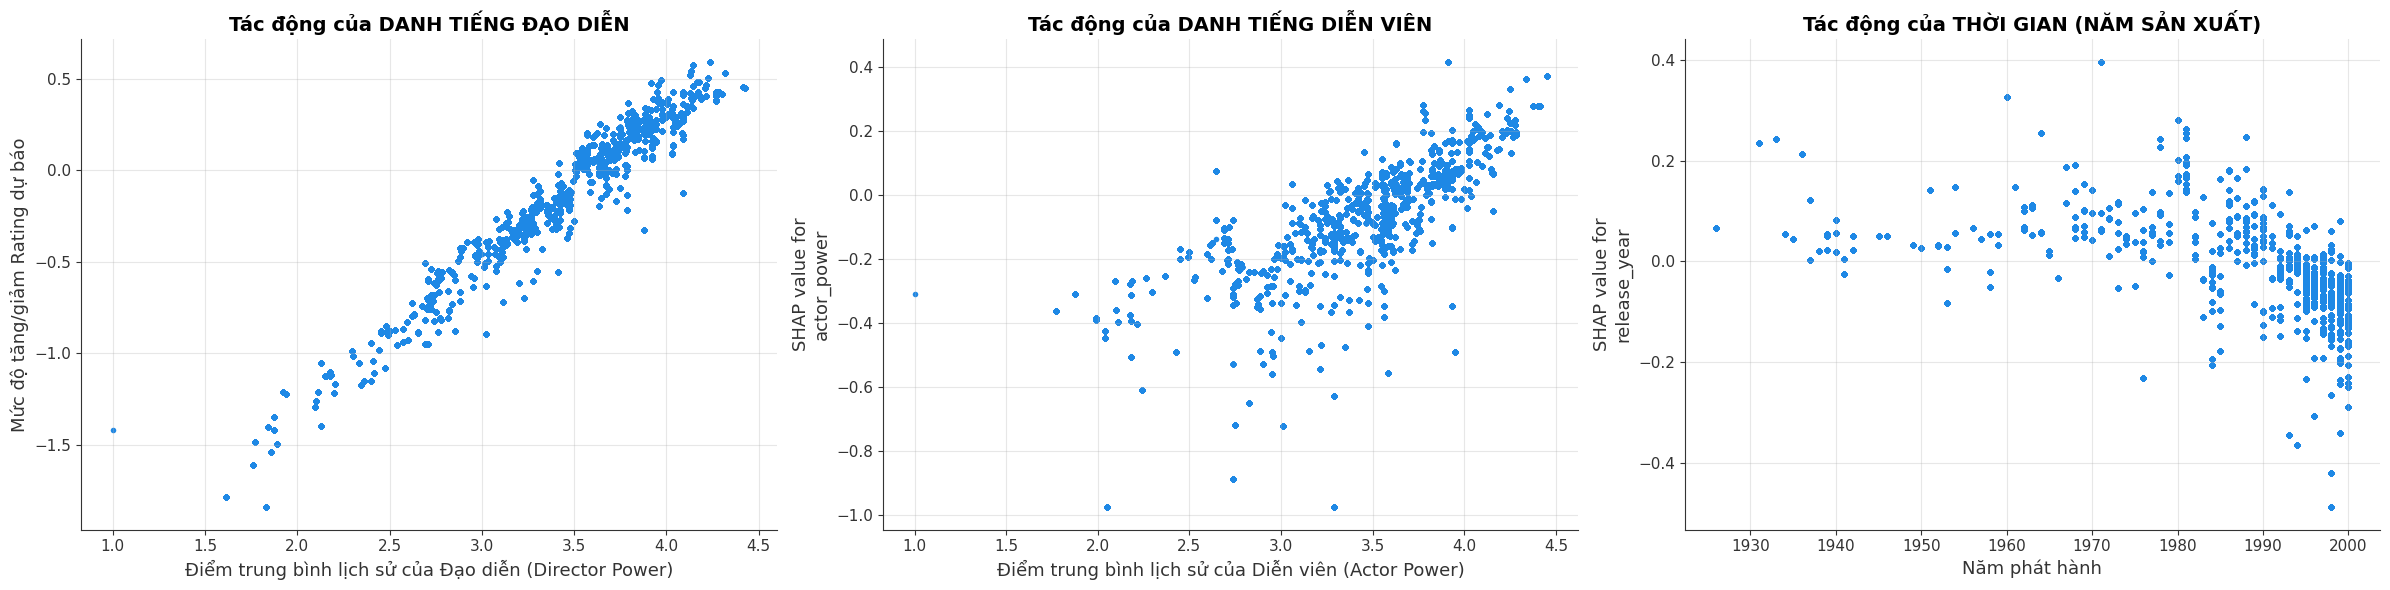

In [133]:
fig, ax = plt.subplots(1, 3, figsize=(24, 6))

# Câu hỏi 1: ĐẠO DIỄN có tên tuổi lớn (Rating lịch sử cao) có kéo điểm phim lên không?
shap.dependence_plot("director_power", shap_values.values, X, interaction_index=None, ax=ax[0], show=False)
ax[0].set_title("Tác động của DANH TIẾNG ĐẠO DIỄN", fontsize=14, fontweight='bold')
ax[0].set_xlabel("Điểm trung bình lịch sử của Đạo diễn (Director Power)")
ax[0].set_ylabel("Mức độ tăng/giảm Rating dự báo")
ax[0].grid(True, alpha=0.3)

# Câu hỏi 2: DIỄN VIÊN có tên tuổi lớn có kéo điểm phim lên không?
shap.dependence_plot("actor_power", shap_values.values, X, interaction_index=None, ax=ax[1], show=False)
ax[1].set_title("Tác động của DANH TIẾNG DIỄN VIÊN", fontsize=14, fontweight='bold')
ax[1].set_xlabel("Điểm trung bình lịch sử của Diễn viên (Actor Power)")
ax[1].grid(True, alpha=0.3)

# Câu hỏi 3: NĂM SẢN XUẤT (Phim cũ vs Mới) ảnh hưởng thế nào?
shap.dependence_plot("release_year", shap_values.values, X, interaction_index=None, ax=ax[2], show=False)
ax[2].set_title("Tác động của THỜI GIAN (NĂM SẢN XUẤT)", fontsize=14, fontweight='bold')
ax[2].set_xlabel("Năm phát hành")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Biểu đồ 1: Ảnh hưởng của Danh tiếng Đạo diễn (Director Power)

Biểu đồ bên trái cho thấy một xu hướng tăng rất rõ ràng, gần như tuyến tính. Khi năng lực hoặc danh tiếng của đạo diễn tăng, điểm số dự đoán của bộ phim (thông qua SHAP value) cũng tăng mạnh theo. Đường xu hướng dốc và chặt chẽ cho thấy mối quan hệ rất bền vững: nếu đạo diễn có mức Power thấp khoảng 2.0, bộ phim có xu hướng bị trừ đến khoảng −1.5 điểm. Ngược lại, khi đạo diễn có chuyên môn cao (Power xấp xỉ 4.0), bộ phim nhận thêm khoảng +0.5 điểm. Điều này chứng minh rằng đạo diễn đóng vai trò then chốt trong chất lượng cuối cùng của một bộ phim. Một đạo diễn yếu kém gần như chắc chắn sẽ kéo điểm phim xuống đáng kể.

Biểu đồ 2: Ảnh hưởng của Danh tiếng Diễn viên (Actor Power)

Biểu đồ ở giữa cũng cho thấy một xu hướng tăng, tuy nhiên độ dốc thấp hơn và dữ liệu phân tán rộng hơn so với đạo diễn. Nghĩa là diễn viên có danh tiếng cao vẫn mang lại giá trị tích cực cho điểm phim, nhưng hiệu ứng này không mạnh và không ổn định như đạo diễn. Biên độ tác động của diễn viên chỉ dao động khoảng từ −0.6 đến +0.4. Sự phân tán dọc tại cùng một mức Power phản ánh thực tế: dù có những diễn viên được đánh giá cao, nhưng không phải phim nào họ tham gia cũng tốt. Vai trò của diễn viên mang tính hỗ trợ nhưng không phải yếu tố quyết định tuyệt đối.

Biểu đồ 3: Ảnh hưởng của Thời gian (Release Year)

Biểu đồ bên phải thể hiện một xu hướng giảm tương đối rõ ràng: phim càng sản xuất về các năm gần đây thì tác động tới điểm cuối càng có xu hướng âm. Các tác phẩm trước những năm 1980 thường có SHAP value > 0, nghĩa là được cộng điểm — đây có thể xem là hiệu ứng ưu ái đối với phim cổ điển. Ngược lại, các phim từ giai đoạn 1990–2000 lại dần bị trừ điểm. Điều này cho thấy tâm lý khắt khe với phim hiện đại: một bộ phim mới có thể bị hụt từ −0.1 đến −0.2 điểm so với phim ra mắt ở giai đoạn cũ, ngay cả khi chất lượng tương đương.

Kết luận:

+ Đạo diễn là yếu tố ảnh hưởng mạnh nhất.

+ Diễn viên tác động tích cực nhưng không ổn định.

+ Năm sản xuất thể hiện xu hướng thiên vị cho phim cổ điển.

#### 5. Tầm quan trọng

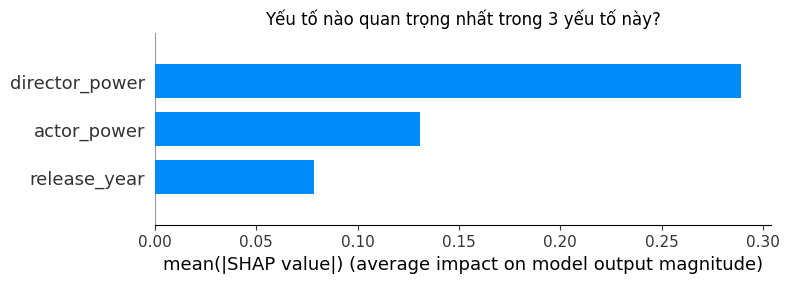

In [134]:
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X, plot_type="bar", show=False)
plt.title("Yếu tố nào quan trọng nhất trong 3 yếu tố này?")
plt.show()

1. Sự thống trị tuyệt đối của Đạo diễn

Các giá trị SHAP cho thấy director_power có mức độ ảnh hưởng vượt trội so với các biến còn lại, đạt khoảng 0.28 — gấp hơn 2,5 lần so với diễn viên và khoảng 5 lần so với năm sản xuất. Kết quả này phản ánh rất đúng bản chất điện ảnh: đạo diễn chính là người định hình chất lượng cuối cùng của bộ phim. Một kịch bản tốt đi kèm đạo diễn yếu có thể trở thành thất bại, trong khi một đạo diễn tài năng vẫn có thể biến các nguồn lực bình thường thành một sản phẩm chất lượng. Vì vậy, trong mô hình dự đoán điểm số, chỉ cần biết ai là đạo diễn đã giúp nâng độ chính xác đáng kể.

2. Vai trò thứ cấp của Diễn viên

Biến actor_power đứng thứ hai với giá trị khoảng 0.12, cho thấy diễn viên nổi tiếng vẫn góp phần nâng điểm phim nhưng không phải yếu tố mang tính quyết định. Nhiều trường hợp phim sở hữu dàn sao lớn nhưng vẫn nhận đánh giá kém khi thiếu sự dẫn dắt tốt từ đạo diễn. Điều này hàm ý rằng diễn viên là yếu tố quan trọng nhưng chỉ mang tính bổ trợ. Khi đạo diễn mạnh, giá trị của diễn viên mới được phát huy trọn vẹn.

3. Ảnh hưởng nhỏ hơn từ Thời gian sản xuất

release_year thể hiện mức độ ảnh hưởng thấp nhất, khoảng 0.05. Mặc dù ở biểu đồ xu hướng trước đó, năm sản xuất có chiều hướng làm giảm điểm phim (đặc biệt ở giai đoạn phim mới), nhưng tác động trung bình chỉ khoảng −0.1 đến −0.2 điểm. So với mức biến động có thể lên tới −1.5 hoặc +0.5 từ đạo diễn, yếu tố thời gian chỉ đóng vai trò điều chỉnh nhỏ. Có thể xem yếu tố năm sản xuất giống như gia vị bổ sung — làm thay đổi nhẹ cảm nhận, nhưng không quyết định chất lượng tổng thể.

Biểu đồ SHAP cho thấy chất lượng phim phụ thuộc chủ yếu vào năng lực đội ngũ sản xuất, đặc biệt là Đạo diễn. Yếu tố thời gian và danh tiếng diễn viên chỉ đóng vai trò bổ trợ.

#### 6. Các phân tích liên quan



##### 6.1 Phân tích "Ma trận Cộng hưởng": Đạo diễn giỏi + Diễn viên giỏi = ?

Phân tích ma trận cộng hưởng cho thấy đạo diễn là yếu tố nền tảng, mang tính quyết định. Vậy, thay vì xem xét riêng lẻ, hãy xem xét sự kết hợp. Liệu một diễn viên ngôi sao có thể "gánh" được một đạo diễn tồi? Hay một đạo diễn tài năng có thể biến diễn viên vô danh thành sao?

a. Phân nhóm theo Phân vị (Quantile Binning)

Thay vì giữ các con số lẻ tẻ (ví dụ: Director Power = 3.45, 4.12...), phương pháp này ép dữ liệu vào 4 giỏ (buckets): Thấp - Trung bình - Cao - Huyền thoại.

Dùng qcut mà thay vì cut:

+ qcut chia dựa trên số lượng (Quantile). Nó đảm bảo nhóm "Low", "Mid", "High", "Legendary" có số lượng phim bằng nhau.

+ Điều này giúp tránh việc một nhóm nào đó quá ít dữ liệu (ví dụ nhóm "High" chỉ có 2 phim) làm sai lệch kết quả trung bình.

In [135]:
# Chia nhóm (Binning) Power thành 4 mức: Low, Medium, High, Legendary

full_data['Director_Tier'] = pd.qcut(full_data['director_power'], q=4, labels=['Low', 'Mid', 'High', 'Legendary'])

full_data['Actor_Tier'] = pd.qcut(full_data['actor_power'], q=4, labels=['Low', 'Mid', 'High', 'Legendary'])

b. Kỹ thuật Bảng chéo (Cross-Tabulation / Pivot Table)

Nguyên lý: Đây là kỹ thuật tạo Ma trận (Matrix). Nó tạo ra một lưới 4x4 (16 ô).

Mục đích: Để xem xét sự giao thoa giữa hai yếu tố. Ví dụ: Tại ô giao nhau giữa Đạo diễn Thấp và Diễn viên Cao, điểm trung bình là bao nhiêu?

In [136]:
# Tạo bảng Pivot
pivot_table = full_data.pivot_table(index='Director_Tier', columns='Actor_Tier', values='Rating', aggfunc='mean')

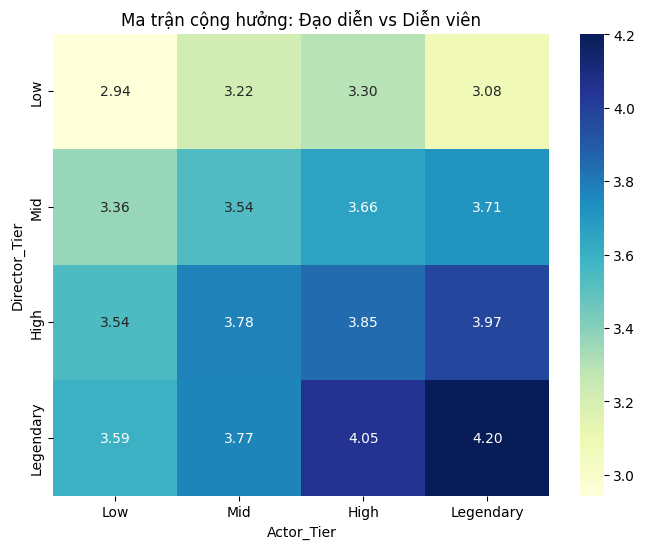

In [137]:
# Vẽ Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu")

plt.title("Ma trận cộng hưởng: Đạo diễn vs Diễn viên")

plt.show()

1. Sự thống trị của Đạo diễn (Director Dominance) Số liệu thực tế khẳng định quyền lực tối thượng thuộc về đạo diễn.

+ Một đạo diễn thuộc nhóm High khi làm việc với diễn viên Low vẫn đạt mức điểm 3.54, cao hơn hẳn trường hợp ngược lại là đạo diễn Low làm việc với diễn viên High (chỉ đạt 3.30).

+ Sự chênh lệch càng khủng khiếp hơn ở phân khúc cao nhất: Một đạo diễn Legendary có thể kéo dàn diễn viên Low lên mức 3.59 (mức Khá), trong khi một diễn viên Legendary hoàn toàn bó tay khi làm việc với đạo diễn Low, bộ phim chỉ đạt 3.08 (mức Trung bình thấp).

-> Đạo diễn là người nắm giữ trần và sàn chất lượng. Một đạo diễn giỏi có thể biến những diễn viên vô danh thành hiện tượng, nhưng một ngôi sao huyền thoại cũng sẽ bị lu mờ nếu đặt vào tay một đạo diễn kém tài.

2. Giới hạn của Diễn viên và "Nghịch lý Huyền thoại"

+ Khi đạo diễn thuộc nhóm Low (hàng trên cùng), sự hiện diện của diễn viên giỏi có giúp cải thiện điểm số, nhưng rất hạn chế: từ 2.94 (Low Actor) lên cao nhất là 3.30 (High Actor).

+ Điểm đặc biệt: chú ý ô trên cùng bên phải. Khi đạo diễn Low kết hợp với diễn viên Legendary, điểm số không tăng mà lại tụt xuống 3.08 (thấp hơn cả khi kết hợp với diễn viên High).

+ Insight: Đây là minh chứng cho thấy diễn viên ngôi sao không phải là "thuốc tiên". Thậm chí, việc đưa một huyền thoại vào một kịch bản/đạo diễn tồi có thể gây phản tác dụng (do kỳ vọng quá cao của khán giả hoặc sự lệch pha trong phong cách), khiến bộ phim bị đánh giá khắt khe hơn. Diễn viên chỉ có thể tỏa sáng rực rỡ nhất khi có bệ phóng là đạo diễn từ mức High trở lên.

3. Vùng Kiệt tác (The Masterpiece Zone)

+ Sự cộng hưởng đạt đỉnh điểm ở ô dưới cùng bên phải: Đạo diễn Legendary kết hợp với Diễn viên Legendary tạo ra mức điểm kỷ lục 4.20.

+ So với điểm xuất phát thấp nhất là 2.94 (Low/Low), sự kết hợp hoàn hảo này nâng tầm bộ phim lên tới 1.26 điểm - một khoảng cách khổng lồ trên thang đo 5 sao.

+ Các mức điểm 4.05 (Legendary Director + High Actor) và 4.20 xác nhận rằng để chạm tới ngưỡng "siêu phẩm" (trên 4.0), vai trò của Đạo diễn Legendary là điều kiện bắt buộc, và Diễn viên tài năng là điều kiện đủ để tối ưu hóa chất lượng đó.

##### 6.2. Phân tích "Ngoại lệ" (Outlier Analysis) 

Chúng ta sẽ đi vào tìm hiểu 2 nhóm chính để trả lời cho câu hỏi: "Bộ phim nào có chất lượng sai lệch nhiều nhất so với thương hiệu của người tạo ra nó?"

A. Nhóm “Sa sút”

Đây là những trường hợp đạo diễn nổi tiếng, tay nghề cao nhưng bộ phim lại bị chấm điểm thấp. Điều này có thể xảy ra khi họ làm phim không đúng sở trường, bị can thiệp bởi nhà sản xuất, hoặc đơn giản là phong độ đi xuống. Nhóm này cho thấy: đạo diễn giỏi cũng có lúc làm ra phim dở.

B. Nhóm “Bứt phá”

Nhóm này gồm những đạo diễn ít tiếng tăm hoặc mới vào nghề, nhưng tác phẩm lại được đánh giá rất cao. Đây thường là những phim có kịch bản xuất sắc, ý tưởng độc đáo hoặc là cú “bật lên” hiếm có của một người mới. Điều này khẳng định: không cần nổi tiếng, chỉ cần nội dung hay vẫn có thể tạo nên siêu phẩm.


=== TOP 10 SA SÚT (Gây thất vọng nhất) ===
                       Title         director  avg_rating  director_power      Diff
            Fair Game (1995)       Doug Liman    2.104167        3.786935 -1.682769
          Mary Reilly (1996)   Stephen Frears    2.340909        3.880931 -1.540022
               Psycho (1998) Alfred Hitchcock    2.651515        3.921470 -1.269955
Beverly Hills Cop III (1994)      John Landis    2.505682        3.747289 -1.241608
     Last Action Hero (1993)   John McTiernan    2.508000        3.647550 -1.139550
                 Hook (1991) Steven Spielberg    3.018006        4.091758 -1.073752
            G.I. Jane (1997)     Ridley Scott    3.052065        4.037769 -0.985704
    Death Becomes Her (1992)  Robert Zemeckis    2.752212        3.728823 -0.976610
               Sphere (1998)   Barry Levinson    2.663586        3.634777 -0.971191
      Renaissance Man (1994)   Penny Marshall    2.870968        3.715354 -0.844386

=== TOP 10 BỨT PHÁ (Gây bất ngờ

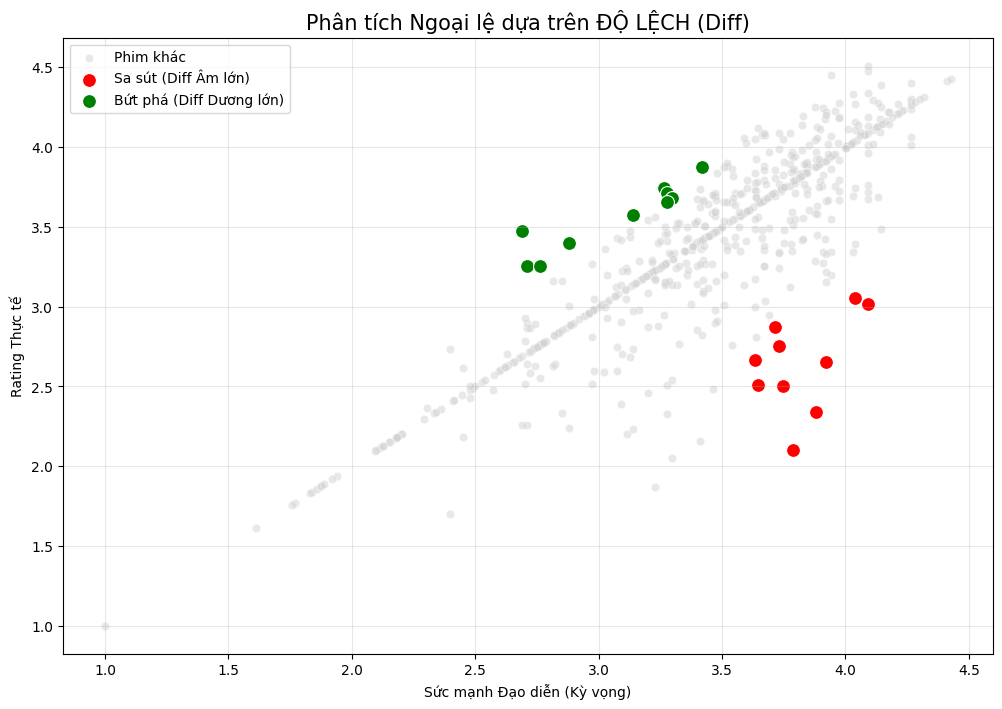

In [138]:
# --- BƯỚC 1: TẠO MOVIE_SUMMARY (KHAI BÁO LẠI CHO CHẮC) ---
# Gom nhóm full_data thành dữ liệu từng phim
movie_summary = full_data.groupby('Title').agg({
    'avg_rating': 'mean',
    'director_power': 'first',
    'director': 'first',
    'Genres': 'first',
    'release_year': 'first',
    'vote_count': 'first'
}).reset_index()

# Lọc bỏ phim ít vote để tránh nhiễu
movie_summary = movie_summary[movie_summary['vote_count'] > 50]

# --- BƯỚC 2: TÍNH ĐỘ LỆCH (DIFF) ---
# Diff = Rating Thực tế - Kỳ vọng (Power)
movie_summary['Diff'] = movie_summary['avg_rating'] - movie_summary['director_power']

# --- BƯỚC 3: LỌC BOM XỊT & HIỆN TƯỢNG ---

# 1. Bom xịt: Kỳ vọng cao (Power > 3.5) nhưng Lệch âm lớn nhất (Thực tế kém xa kỳ vọng)
flops = movie_summary[movie_summary['director_power'] > 3.5].sort_values('Diff', ascending=True).head(10)

# 2. Hiện tượng: Kỳ vọng thấp (Power < 3.5) nhưng Lệch dương lớn nhất (Thực tế vượt xa kỳ vọng)
breakouts = movie_summary[movie_summary['director_power'] < 3.5].sort_values('Diff', ascending=False).head(10)

# --- BƯỚC 4: IN KẾT QUẢ ---
cols = ['Title', 'director', 'avg_rating', 'director_power', 'Diff']

print("\n=== TOP 10 SA SÚT (Gây thất vọng nhất) ===")
print(flops[cols].to_string(index=False))

print("\n=== TOP 10 BỨT PHÁ (Gây bất ngờ nhất) ===")
print(breakouts[cols].to_string(index=False))

# --- BƯỚC 5: TRỰC QUAN HÓA ---
plt.figure(figsize=(12, 8))
# Vẽ nền
sns.scatterplot(data=movie_summary, x='director_power', y='avg_rating', color='lightgrey', alpha=0.5, label='Phim khác')
# Vẽ Bom xịt
sns.scatterplot(data=flops, x='director_power', y='avg_rating', color='red', s=100, label='Sa sút (Diff Âm lớn)')
# Vẽ Hiện tượng
sns.scatterplot(data=breakouts, x='director_power', y='avg_rating', color='green', s=100, label='Bứt phá (Diff Dương lớn)')

plt.title('Phân tích Ngoại lệ dựa trên ĐỘ LỆCH (Diff)', fontsize=15)
plt.xlabel('Sức mạnh Đạo diễn (Kỳ vọng)')
plt.ylabel('Rating Thực tế')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Dữ liệu về nhóm phim gây thất vọng cho thấy một mô hình rõ rệt: đây đều là các tác phẩm do những đạo diễn có uy tín cao chỉ đạo, nhưng điểm số thực tế lại rơi xuống mức rất thấp. Một phát hiện quan trọng trong nhóm này là trường hợp Psycho (1998), nơi dữ liệu đã ghép nhầm đạo diễn Alfred Hitchcock của bản gốc với bản làm lại năm 1998 của Gus Van Sant. Vì Hitchcock có power gần 4.0, kỳ vọng bị đẩy lên quá cao, trong khi bản remake bị chê dữ dội, dẫn đến sự lệch lớn và bị phân loại là “phim gây thất vọng”. Các ví dụ khác như Hook (Steven Spielberg) hay G.I. Jane (Ridley Scott) cho thấy ngay cả những đạo diễn huyền thoại cũng có thể tạo ra các tác phẩm không đạt kỳ vọng khi thay đổi phong cách hoặc gặp vấn đề trong quá trình sản xuất.

Ở chiều ngược lại, nhóm phim gây bất ngờ tập trung vào các đạo diễn có mức độ uy tín thấp đến trung bình, nhưng tác phẩm của họ lại đạt điểm số cao vượt trội. Bên cạnh đó, nhóm các phim “bất ngờ thật sự” hiện lên rõ nét, đặc biệt trong dòng phim kinh dị như Halloween hay Scream. Đây là những tác phẩm mà các đạo diễn còn ít tên tuổi đã tạo ra dấu ấn mạnh bằng kịch bản độc đáo hoặc phong cách mới mẻ, cho thấy thể loại này có khả năng tạo ra những cú bứt phá ngay cả khi đội ngũ sản xuất chưa có danh tiếng lớn.

Từ hai nhóm đối lập này, có thể đưa ra vài kết luận quan trọng cho báo cáo. Đầu tiên, chỉ số Diff hoạt động chính xác trong việc phát hiện sự lệch giữa kỳ vọng và thực tế, phản ánh đúng tâm lý khán giả: thất vọng không đến từ phim dở mà đến từ phim dở so với danh tiếng đạo diễn. Cuối cùng, kết quả cho thấy chiến lược đầu tư vào các đạo diễn trẻ trong dòng phim kinh dị hoặc hành động có thể mang lại hiệu quả cao, bởi những thể loại này có tỷ lệ xuất hiện “breakout” vượt trội so với các nhóm phim khác.

Phân phối nhãn dự báo:
Fate
2    526
1     59
0     32
Name: count, dtype: int64

Đang huấn luyện mô hình dự báo...

KẾT QUẢ DỰ BÁO:
                    precision    recall  f1-score   support

     Sa sút (Flop)       0.40      0.33      0.36         6
Bứt phá (Breakout)       0.25      0.25      0.25        12
       Bình thường       0.88      0.89      0.88       106

          accuracy                           0.80       124
         macro avg       0.51      0.49      0.50       124
      weighted avg       0.79      0.80      0.80       124



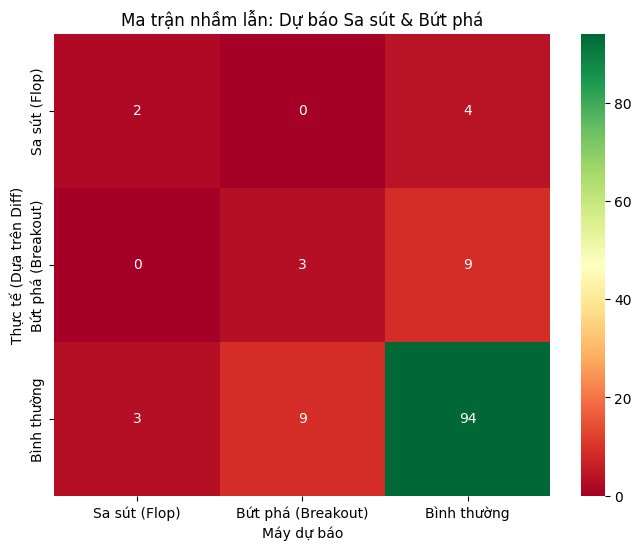

In [139]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- BƯỚC 1: TẠO NHÃN (LABELING) DỰA TRÊN LOGIC "ĐỘ LỆCH" (DIFF) ---
# Sử dụng lại movie_summary từ bước trước

# 1. Xác định ngưỡng (Dùng Quantile để linh hoạt)
high_power_thresh = movie_summary['director_power'].quantile(0.80) # Top 20% quyền lực
low_power_thresh = movie_summary['director_power'].quantile(0.50)  # Bottom 50%
diff_low_thresh = movie_summary['Diff'].quantile(0.20)  # Top 20% gây thất vọng nhất
diff_high_thresh = movie_summary['Diff'].quantile(0.80) # Top 20% gây bất ngờ nhất

# 2. Hàm dán nhãn
def get_movie_fate(row):
    # Nhóm Sa sút (Flop): Đạo diễn xịn + Diff Âm lớn
    if (row['director_power'] >= high_power_thresh) and (row['Diff'] <= diff_low_thresh):
        return 0 # Mã 0: SA SÚT
    
    # Nhóm Bứt phá (Breakout): Đạo diễn thường + Diff Dương lớn
    elif (row['director_power'] <= low_power_thresh) and (row['Diff'] >= diff_high_thresh):
        return 1 # Mã 1: BỨT PHÁ
    
    # Còn lại là Bình thường
    else:
        return 2 # Mã 2: BÌNH THƯỜNG

# Áp dụng hàm để tạo cột mục tiêu (Target)
movie_summary['Fate'] = movie_summary.apply(get_movie_fate, axis=1)

print("Phân phối nhãn dự báo:")
print(movie_summary['Fate'].value_counts())
# Bạn sẽ thấy nhóm 0 và 1 khá ít, nhóm 2 chiếm đa số -> Đây là bài toán mất cân bằng dữ liệu

# --- BƯỚC 2: CHUẨN BỊ DỮ LIỆU HUẤN LUYỆN (FEATURES) ---
# Input (X): Chỉ dùng thông tin CÓ TRƯỚC khi phim chiếu
# TUYỆT ĐỐI KHÔNG dùng 'Rating' hay 'Diff' trong X (vì đó là đáp án)
feature_cols = ['director_power', 'release_year'] 
# Nếu bạn có thêm budget hay genres ở movie_summary thì thêm vào đây sẽ tốt hơn

X = movie_summary[feature_cols]
y = movie_summary['Fate']

# Chia tập Train/Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- BƯỚC 3: HUẤN LUYỆN MÔ HÌNH ---
# class_weight='balanced': Cực kỳ quan trọng để máy chú ý vào nhóm thiểu số (Sa sút/Bứt phá)
print("\nĐang huấn luyện mô hình dự báo...")
clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

# --- BƯỚC 4: ĐÁNH GIÁ & TRỰC QUAN HÓA ---
y_pred = clf.predict(X_test)

# In báo cáo
target_names = ['Sa sút (Flop)', 'Bứt phá (Breakout)', 'Bình thường']
print("\n" + "="*40)
print("KẾT QUẢ DỰ BÁO:")
print("="*40)
print(classification_report(y_test, y_pred, target_names=target_names))

# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdYlGn', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Ma trận nhầm lẫn: Dự báo Sa sút & Bứt phá')
plt.ylabel('Thực tế (Dựa trên Diff)')
plt.xlabel('Máy dự báo')
plt.show()

Kết quả phân loại ba nhóm phim (Sa sút – Bứt phá – Bình thường) vẽ nên một bức tranh thực tế vừa có điểm sáng, vừa còn nhiều "vùng tối" cần khắc phục. Mặc dù độ chính xác tổng thể (Accuracy) đạt mức xấp xỉ 80% (99/124 mẫu đúng), con số này chủ yếu đến từ việc mô hình nhận diện rất tốt nhóm đa số là "Bình thường" (bắt đúng 94/106 trường hợp). Tuy nhiên, khi đi sâu vào hai nhóm thiểu số quan trọng nhất đối với chiến lược đầu tư, hiệu năng của mô hình bộc lộ những giới hạn rõ rệt.

Đối với nhóm Sa sút (Flop): Mô hình thể hiện vai trò "người gác cổng" ở mức độ chấp nhận được.

+ Precision (Độ chính xác dự báo): Trong 5 lần mô hình cảnh báo phim có nguy cơ "Sa sút", có 2 lần dự đoán đúng (40%). Dù chưa quá cao, nhưng tỷ lệ này đủ để làm tín hiệu cảnh báo sớm, giúp nhà đầu tư cân nhắc kỹ trước khi xuống tiền.

+ Recall (Độ nhạy): Điểm yếu nằm ở việc mô hình bỏ sót khá nhiều rủi ro. Thực tế có 6 phim sa sút, nhưng mô hình chỉ phát hiện được 2, còn lại 4 trường hợp đã bị "lọt lưới" và nhầm sang nhóm Bình thường.

Đối với nhóm Bứt phá (Breakout): Đây là bài toán khó khăn nhất.

+ Precision & Recall đồng mức 25%: Mô hình dự báo được 12 phim sẽ bứt phá, nhưng chỉ có 3 phim thực sự làm được điều đó (Precision 25%), còn lại 9 phim chỉ ở mức bình thường (False Positive). Ngược lại, trong tổng số 12 phim bứt phá thực tế, mô hình cũng chỉ "gọi tên" được 3, bỏ lỡ tới 9 "viên ngọc quý" (False Negative).

+ Sự nhầm lẫn hai chiều: Đáng chú ý là sự nhầm lẫn giữa nhóm "Bứt phá" và "Bình thường" diễn ra rất mạnh ở cả hai chiều (số lượng nhầm lẫn là 9 ở mỗi ô). Điều này cho thấy ranh giới giữa một bộ phim thành công bất ngờ và một bộ phim bình thường vẫn còn rất mờ nhạt đối với các đặc trưng hiện tại của mô hình.

Nguyên nhân cốt lõi: Vấn đề muôn thuở vẫn là Mất cân bằng dữ liệu. Nhóm "Bình thường" áp đảo với 106 mẫu, hoạt động như một "hố đen" hút các dự đoán về phía mình. Nhóm Sa sút (6 mẫu) và Bứt phá (12 mẫu) quá ít ỏi, khiến mô hình chưa đủ dữ kiện để học được các quy luật tinh vi phân biệt chúng với nhóm đa số.

